In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
file_path = "../DATA/raw/safety_incidents_synthetic_raw.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset loaded successfully!
Number of rows: 8000
Number of columns: 30


In [3]:
# Display the first five records
display(df.head())

# Display all column names
print("Column names:")
print(df.columns.tolist())

# Check data types and missing values
df.info()

,incident_id,incident_date,incident_time,department,location,shift,employee_role,experience_level,equipment_type,equipment_status,...,severity_level,risk_level,risk_score,immediate_action,corrective_action,preventive_action,reported_by_role,investigation_status,incident_status,lost_time_days
0,INC-2021-00001,2021-01-01,00:09,Chemical Processing,Effluent Treatment Plant,Night,Process Technician,1-3 years,Chemical Storage Cabinet,Damaged,...,Serious,High,61.9,"Employee moved to fresh air, contaminated clot...",Review the chemical transfer and handling meth...,"Set up PPE compliance audits, stock availabili...",Shift Manager,Completed,Closed,8
1,INC-2021-00002,2021-01-01,05:10,Assembly,Assembly Line B,Night,Line Supervisor,3-7 years,Pneumatic Tool,Operational,...,Serious,High,52.6,Machine stopped and isolated; injured employee...,"Inspect the air-powered driver, repair or repl...","Implement permit-to-work audits, lock-out/tag-...",Supervisor,Completed,Closed,17
2,INC-2021-00003,2021-01-01,07:25,Production,Machining Bay,Morning,Production Technician,More than 7 years,Forklift,Operational,...,Minor,Medium,27.6,Area secured and injured employee sent to the ...,"Secure loose material, install a barrier aroun...",Standardise the shift handover format and use ...,Supervisor,Completed,Closed,0
3,INC-2021-00004,2021-01-01,08:52,Quality Control & Laboratory,Incoming Inspection,Morning,Quality Inspector,3-7 years,Fume Hood,Operational,...,Minor,Medium,27.8,"Employee moved to fresh air, contaminated clot...",Review the chemical transfer and handling meth...,Standardise the shift handover format and use ...,Supervisor,Completed,Closed,0
4,INC-2021-00005,2021-01-01,09:26,Assembly,Sub-assembly Area,Morning,Assembly Operator,More than 7 years,Not Applicable,Not Applicable,...,Moderate,Low,19.3,Task rotated and injured employee sent for med...,"Adjust the workstation layout, provide adjusta...",Include HSE review at the design and modificat...,Co-worker,Completed,Closed,1


Column names:
['incident_id', 'incident_date', 'incident_time', 'department', 'location', 'shift', 'employee_role', 'experience_level', 'equipment_type', 'equipment_status', 'incident_type', 'hazard_type', 'incident_description', 'injury_type', 'body_part_affected', 'medical_treatment_required', 'root_cause_category', 'root_cause_description', 'contributing_factor_1', 'contributing_factor_2', 'severity_level', 'risk_level', 'risk_score', 'immediate_action', 'corrective_action', 'preventive_action', 'reported_by_role', 'investigation_status', 'incident_status', 'lost_time_days']
<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 30 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   incident_id                 8000 non-null   str    
 1   incident_date               8000 non-null   str    
 2   incident_time               8000 non-null   str    
 3   department                  8

In [4]:
# Count missing values in every column
missing_values = df.isnull().sum()

display(
    missing_values[missing_values > 0]
    .sort_values(ascending=False)
)

# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Check duplicate incident IDs
print("Duplicate incident IDs:", df["incident_id"].duplicated().sum())

contributing_factor_2     2578
injury_type               1135
body_part_affected        1135
experience_level           148
reported_by_role            87
equipment_status            63
employee_role               50
root_cause_description      41
dtype: int64

Duplicate rows: 0
Duplicate incident IDs: 0


In [5]:
print("Root cause categories:")
print(df["root_cause_category"].value_counts())

print("\nNumber of unique root cause categories:")
print(df["root_cause_category"].nunique())

print("\nMissing incident descriptions:",
      df["incident_description"].isnull().sum())

print("Missing root cause labels:",
      df["root_cause_category"].isnull().sum())

Root cause categories:
root_cause_category
Procedure Violation           905
Human Error                   894
Poor Housekeeping             787
Unsafe Working Condition      694
Inadequate Training           669
Fatigue/Workload              567
Poor Maintenance              495
Inadequate Risk Assessment    487
Supervision Failure           451
Design Deficiency             413
Equipment Failure             384
Communication Failure         359
PPE Non-Compliance            352
Environmental Condition       348
Other                         195
Name: count, dtype: int64

Number of unique root cause categories:
15

Missing incident descriptions: 0
Missing root cause labels: 0


In [6]:
import pandas as pd
import re

# Keep the original dataset unchanged
df_clean = df[[
    "incident_description",
    "root_cause_category"
]].copy()

# Remove leading and trailing whitespace
df_clean["incident_description"] = (
    df_clean["incident_description"].astype("string").str.strip()
)

df_clean["root_cause_category"] = (
    df_clean["root_cause_category"].astype("string").str.strip()
)

# Convert empty strings to missing values
df_clean = df_clean.replace(r"^\s*$", pd.NA, regex=True)

# Remove rows with missing input text or target labels
df_clean = df_clean.dropna(
    subset=["incident_description", "root_cause_category"]
)

# Remove exact duplicate input-label pairs
df_clean = df_clean.drop_duplicates(
    subset=["incident_description", "root_cause_category"]
).reset_index(drop=True)

print("Rows after basic cleaning:", len(df_clean))
print("Missing values:")
print(df_clean.isnull().sum())

print("Duplicate input-label pairs:",
      df_clean.duplicated().sum())

Rows after basic cleaning: 8000
Missing values:
incident_description    0
root_cause_category     0
dtype: int64
Duplicate input-label pairs: 0


In [7]:
def clean_text(text):
    text = str(text).lower()

    # Remove HTML tags
    text = re.sub(r"<[^>]+>", " ", text)

    # Remove URLs
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    # Replace punctuation and special characters with spaces
    # Preserve letters and numbers
    text = re.sub(r"[^a-z0-9\s]", " ", text)

    # Normalize multiple spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text


df_clean["clean_description"] = (
    df_clean["incident_description"].apply(clean_text)
)

# Remove descriptions that became empty after preprocessing
df_clean = df_clean[
    df_clean["clean_description"].str.strip().ne("")
].reset_index(drop=True)

print("Rows after text cleaning:", len(df_clean))

Rows after text cleaning: 8000


In [8]:
for i in range(3):
    print("ORIGINAL:")
    print(df_clean.loc[i, "incident_description"])

    print("\nCLEANED:")
    print(df_clean.loc[i, "clean_description"])

    print("\nROOT CAUSE:")
    print(df_clean.loc[i, "root_cause_category"])

    print("-" * 80)

ORIGINAL:
A process technician came into contact with caustic solution during sampling at the chemical storage cabinet. She was not wearing the required chemical-resistant gloves. She was referred to a specialist for an inhalation injury and could not perform normal duties for weeks.

CLEANED:
a process technician came into contact with caustic solution during sampling at the chemical storage cabinet she was not wearing the required chemical resistant gloves she was referred to a specialist for an inhalation injury and could not perform normal duties for weeks

ROOT CAUSE:
PPE Non-Compliance
--------------------------------------------------------------------------------
ORIGINAL:
At around 5:10 am, a cutting blade on the air-powered driver sliced the line supervisor while he was changing the accessory. The guard had been removed and the machine was left running while he cleaned it. He needed treatment at a nearby hospital for a crush injury to his arm and lost working days.

CLEANED:


In [9]:
print("Number of records:", len(df_clean))
print("Number of root-cause categories:",
      df_clean["root_cause_category"].nunique())

display(
    df_clean["root_cause_category"]
    .value_counts()
    .to_frame("Number of incidents")
)

Number of records: 8000
Number of root-cause categories: 15


,Number of incidents
root_cause_category,
Procedure Violation,905
Human Error,894
Poor Housekeeping,787
Unsafe Working Condition,694
Inadequate Training,669
Fatigue/Workload,567
Poor Maintenance,495
Inadequate Risk Assessment,487
Supervision Failure,451


In [10]:
# Preserve every original column
df_full = df.copy()

# Add the cleaned incident narrative
df_full["clean_description"] = (
    df_full["incident_description"]
    .apply(clean_text)
)

print("Original dataset:", df.shape)
print("Full working dataset:", df_full.shape)

display(df_full.head())


Original dataset: (8000, 30)
Full working dataset: (8000, 31)


,incident_id,incident_date,incident_time,department,location,shift,employee_role,experience_level,equipment_type,equipment_status,...,risk_level,risk_score,immediate_action,corrective_action,preventive_action,reported_by_role,investigation_status,incident_status,lost_time_days,clean_description
0,INC-2021-00001,2021-01-01,00:09,Chemical Processing,Effluent Treatment Plant,Night,Process Technician,1-3 years,Chemical Storage Cabinet,Damaged,...,High,61.9,"Employee moved to fresh air, contaminated clot...",Review the chemical transfer and handling meth...,"Set up PPE compliance audits, stock availabili...",Shift Manager,Completed,Closed,8,a process technician came into contact with ca...
1,INC-2021-00002,2021-01-01,05:10,Assembly,Assembly Line B,Night,Line Supervisor,3-7 years,Pneumatic Tool,Operational,...,High,52.6,Machine stopped and isolated; injured employee...,"Inspect the air-powered driver, repair or repl...","Implement permit-to-work audits, lock-out/tag-...",Supervisor,Completed,Closed,17,at around 5 10 am a cutting blade on the air p...
2,INC-2021-00003,2021-01-01,07:25,Production,Machining Bay,Morning,Production Technician,More than 7 years,Forklift,Operational,...,Medium,27.6,Area secured and injured employee sent to the ...,"Secure loose material, install a barrier aroun...",Standardise the shift handover format and use ...,Supervisor,Completed,Closed,0,a worker was hit by a pallet being moved by a ...
3,INC-2021-00004,2021-01-01,08:52,Quality Control & Laboratory,Incoming Inspection,Morning,Quality Inspector,3-7 years,Fume Hood,Operational,...,Medium,27.8,"Employee moved to fresh air, contaminated clot...",Review the chemical transfer and handling meth...,Standardise the shift handover format and use ...,Supervisor,Completed,Closed,0,a quality inspector inhaled fumes while cleani...
4,INC-2021-00005,2021-01-01,09:26,Assembly,Sub-assembly Area,Morning,Assembly Operator,More than 7 years,Not Applicable,Not Applicable,...,Low,19.3,Task rotated and injured employee sent for med...,"Adjust the workstation layout, provide adjusta...",Include HSE review at the design and modificat...,Co-worker,Completed,Closed,1,an assembly operator experienced strain while ...


In [11]:
print("Risk level distribution:")
display(df_full["risk_level"].value_counts(dropna=False))

print("\nRisk score summary:")
display(df_full["risk_score"].describe())

print("\nRisk score by risk level:")
display(
    df_full.groupby("risk_level", dropna=False)["risk_score"]
    .agg(["count", "min", "mean", "max"])
    .sort_values("mean")
)

Risk level distribution:


risk_level
Medium      3323
High        2109
Low         2009
Critical     559
Name: count, dtype: int64


Risk score summary:


count    8000.000000
mean       41.610238
std        20.654510
min         1.900000
25%        25.000000
50%        39.500000
75%        56.300000
max       100.000000
Name: risk_score, dtype: float64


Risk score by risk level:


,count,min,mean,max
risk_level,,,,
Low,2009,1.9,16.733051,25.0
Medium,3323,25.1,37.342401,50.0
High,2109,50.1,61.037364,75.0
Critical,559,75.1,83.092308,100.0


In [12]:
# 1. Check dataset dimensions
print("Dataset shape:", df_full.shape)

# 2. Check data types
print("\nColumn data types:")
display(df_full.dtypes.to_frame("Data Type"))

# 3. Check missing values across ALL columns
missing = df_full.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Count": missing,
    "Missing Percentage": (missing / len(df_full) * 100).round(2)
})

display(
    missing_summary[missing_summary["Missing Count"] > 0]
    .sort_values("Missing Percentage", ascending=False)
)

# 4. Check exact duplicate rows
print("\nExact duplicate rows:", df_full.duplicated().sum())

# 5. Check duplicate incident IDs
print(
    "Duplicate incident IDs:",
    df_full["incident_id"].duplicated().sum()
)

# 6. Check whitespace and inconsistent categories
categorical_columns = [
    "department",
    "location",
    "shift",
    "incident_type",
    "hazard_type",
    "root_cause_category",
    "severity_level",
    "risk_level"
]

for col in categorical_columns:
    print(f"\n{col}:")
    print("Unique values:", df_full[col].nunique())
    print(df_full[col].value_counts(dropna=False).head(10))

Dataset shape: (8000, 31)

Column data types:


,Data Type
incident_id,str
incident_date,str
incident_time,str
department,str
location,str
shift,str
employee_role,str
experience_level,str
equipment_type,str
equipment_status,str


,Missing Count,Missing Percentage
contributing_factor_2,2578,32.22
injury_type,1135,14.19
body_part_affected,1135,14.19
experience_level,148,1.85
reported_by_role,87,1.09
equipment_status,63,0.79
employee_role,50,0.62
root_cause_description,41,0.51



Exact duplicate rows: 0
Duplicate incident IDs: 0

department:
Unique values: 11
department
Production                      1730
Warehouse & Logistics           1205
Maintenance                     1069
Assembly                         776
Fabrication & Welding            709
Chemical Processing              637
Electrical                       548
Packaging                        530
Utilities                        414
Quality Control & Laboratory     220
Name: count, dtype: int64

location:
Unique values: 54
location
Plant Floor             326
Machining Bay           300
Production Line 2       300
Press Shop              292
Stamping Area           291
Production Line 1       280
Moulding Area           267
Maintenance Workshop    241
Yard                    220
Assembly Line B         207
Name: count, dtype: int64

shift:
Unique values: 3
shift
Morning    3676
Evening    2608
Night      1716
Name: count, dtype: int64

incident_type:
Unique values: 20
incident_type
Slip/Fall     

In [13]:
import pandas as pd
import numpy as np

# Keep the original dataset unchanged
df_cleaned = df_full.copy()

# Step 1: Clean whitespace in all text columns
text_columns = df_cleaned.select_dtypes(
    include=["object", "string"]
).columns

for col in text_columns:
    df_cleaned[col] = df_cleaned[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

# Step 2: Convert empty strings into missing values
df_cleaned.replace(r"^\s*$", pd.NA, regex=True, inplace=True)

# Step 3: Convert incident_date to datetime
df_cleaned["incident_date"] = pd.to_datetime(
    df_cleaned["incident_date"],
    errors="coerce"
)

# Step 4: Validate incident_time
# Expected format: HH:MM
time_parsed = pd.to_datetime(
    df_cleaned["incident_time"],
    format="%H:%M",
    errors="coerce"
)

print("Invalid or missing dates:",
      df_cleaned["incident_date"].isna().sum())

print("Invalid or missing times:",
      time_parsed.isna().sum())

# Step 5: Check numerical values
print("\nRisk scores outside 1-100:",
      (~df_cleaned["risk_score"].between(1, 100)).sum())

print("Negative lost-time days:",
      (df_cleaned["lost_time_days"] < 0).sum())

# Step 6: Verify that columns and records are preserved
print("\nOriginal shape:", df_full.shape)
print("Cleaned shape:", df_cleaned.shape)

print("\nMissing values after cleaning:")
display(
    df_cleaned.isnull().sum()
    .loc[lambda x: x > 0]
    .sort_values(ascending=False)
)

print("\nCleaned dataset preview:")
display(df_cleaned.head())

Invalid or missing dates: 0
Invalid or missing times: 0

Risk scores outside 1-100: 0
Negative lost-time days: 0

Original shape: (8000, 31)
Cleaned shape: (8000, 31)

Missing values after cleaning:


contributing_factor_2     2578
injury_type               1135
body_part_affected        1135
experience_level           148
reported_by_role            87
equipment_status            63
employee_role               50
root_cause_description      41
dtype: int64


Cleaned dataset preview:


,incident_id,incident_date,incident_time,department,location,shift,employee_role,experience_level,equipment_type,equipment_status,...,risk_level,risk_score,immediate_action,corrective_action,preventive_action,reported_by_role,investigation_status,incident_status,lost_time_days,clean_description
0,INC-2021-00001,2021-01-01,00:09,Chemical Processing,Effluent Treatment Plant,Night,Process Technician,1-3 years,Chemical Storage Cabinet,Damaged,...,High,61.9,"Employee moved to fresh air, contaminated clot...",Review the chemical transfer and handling meth...,"Set up PPE compliance audits, stock availabili...",Shift Manager,Completed,Closed,8,a process technician came into contact with ca...
1,INC-2021-00002,2021-01-01,05:10,Assembly,Assembly Line B,Night,Line Supervisor,3-7 years,Pneumatic Tool,Operational,...,High,52.6,Machine stopped and isolated; injured employee...,"Inspect the air-powered driver, repair or repl...","Implement permit-to-work audits, lock-out/tag-...",Supervisor,Completed,Closed,17,at around 5 10 am a cutting blade on the air p...
2,INC-2021-00003,2021-01-01,07:25,Production,Machining Bay,Morning,Production Technician,More than 7 years,Forklift,Operational,...,Medium,27.6,Area secured and injured employee sent to the ...,"Secure loose material, install a barrier aroun...",Standardise the shift handover format and use ...,Supervisor,Completed,Closed,0,a worker was hit by a pallet being moved by a ...
3,INC-2021-00004,2021-01-01,08:52,Quality Control & Laboratory,Incoming Inspection,Morning,Quality Inspector,3-7 years,Fume Hood,Operational,...,Medium,27.8,"Employee moved to fresh air, contaminated clot...",Review the chemical transfer and handling meth...,Standardise the shift handover format and use ...,Supervisor,Completed,Closed,0,a quality inspector inhaled fumes while cleani...
4,INC-2021-00005,2021-01-01,09:26,Assembly,Sub-assembly Area,Morning,Assembly Operator,More than 7 years,Not Applicable,Not Applicable,...,Low,19.3,Task rotated and injured employee sent for med...,"Adjust the workstation layout, provide adjusta...",Include HSE review at the design and modificat...,Co-worker,Completed,Closed,1,an assembly operator experienced strain while ...


In [14]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

Incident Severity Distribution


severity_level
Minor       2721
Moderate    2700
Serious     1639
Severe       777
Critical     163
Name: count, dtype: int64

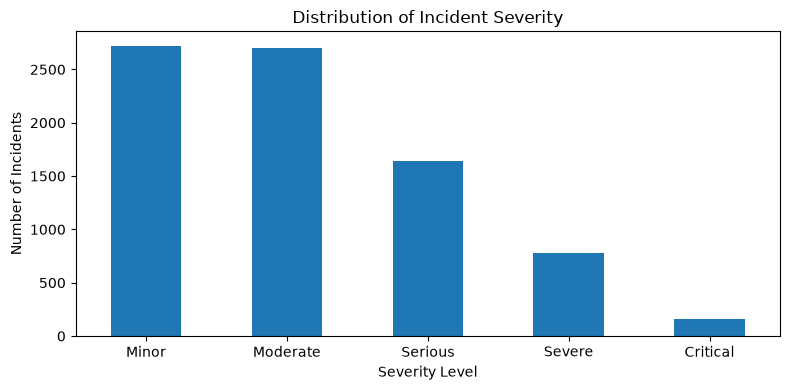

Risk Level Distribution


risk_level
Medium      3323
High        2109
Low         2009
Critical     559
Name: count, dtype: int64

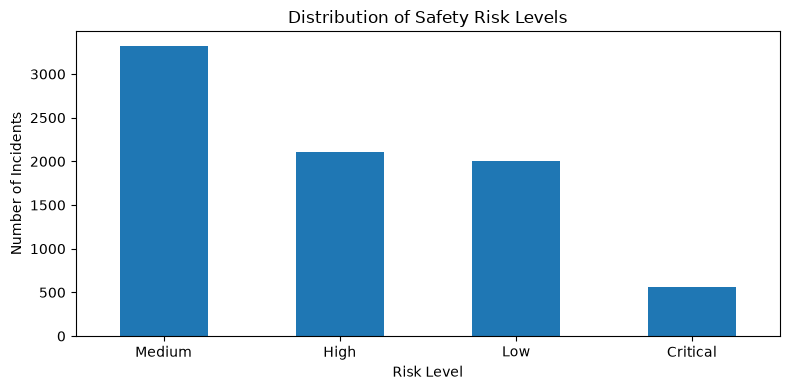

In [15]:
# Incident severity distribution
print("Incident Severity Distribution")
display(df_cleaned["severity_level"].value_counts())

df_cleaned["severity_level"].value_counts().plot(
    kind="bar",
    figsize=(8, 4)
)

plt.title("Distribution of Incident Severity")
plt.xlabel("Severity Level")
plt.ylabel("Number of Incidents")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# Risk level distribution
print("Risk Level Distribution")
display(df_cleaned["risk_level"].value_counts())

df_cleaned["risk_level"].value_counts().plot(
    kind="bar",
    figsize=(8, 4)
)

plt.title("Distribution of Safety Risk Levels")
plt.xlabel("Risk Level")
plt.ylabel("Number of Incidents")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

,Incident Count
root_cause_category,
Procedure Violation,905
Human Error,894
Poor Housekeeping,787
Unsafe Working Condition,694
Inadequate Training,669
Fatigue/Workload,567
Poor Maintenance,495
Inadequate Risk Assessment,487
Supervision Failure,451


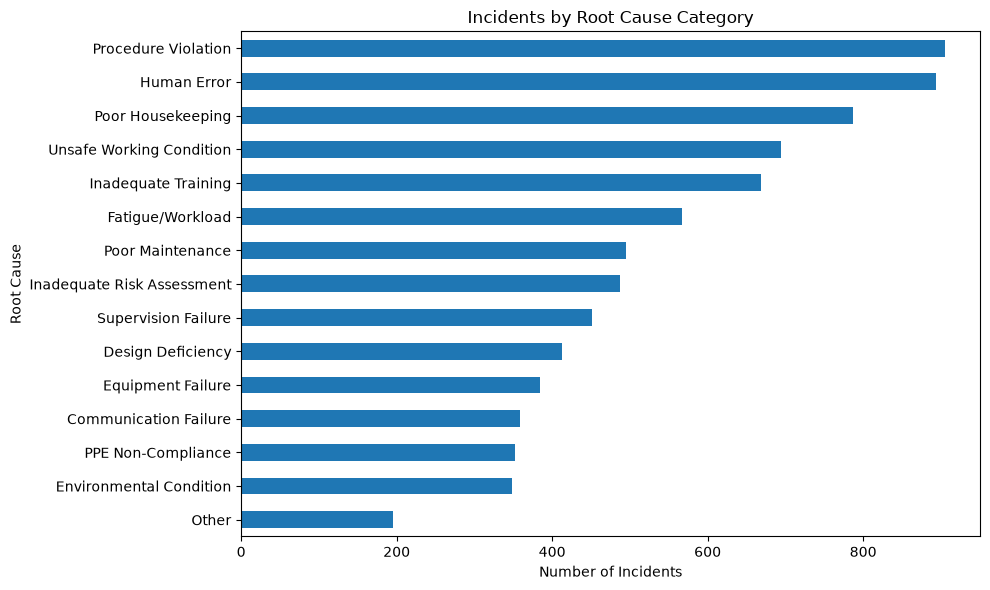

In [16]:
root_causes = df_cleaned["root_cause_category"].value_counts()

display(root_causes.to_frame("Incident Count"))

root_causes.sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Incidents by Root Cause Category")
plt.xlabel("Number of Incidents")
plt.ylabel("Root Cause")
plt.tight_layout()
plt.show()

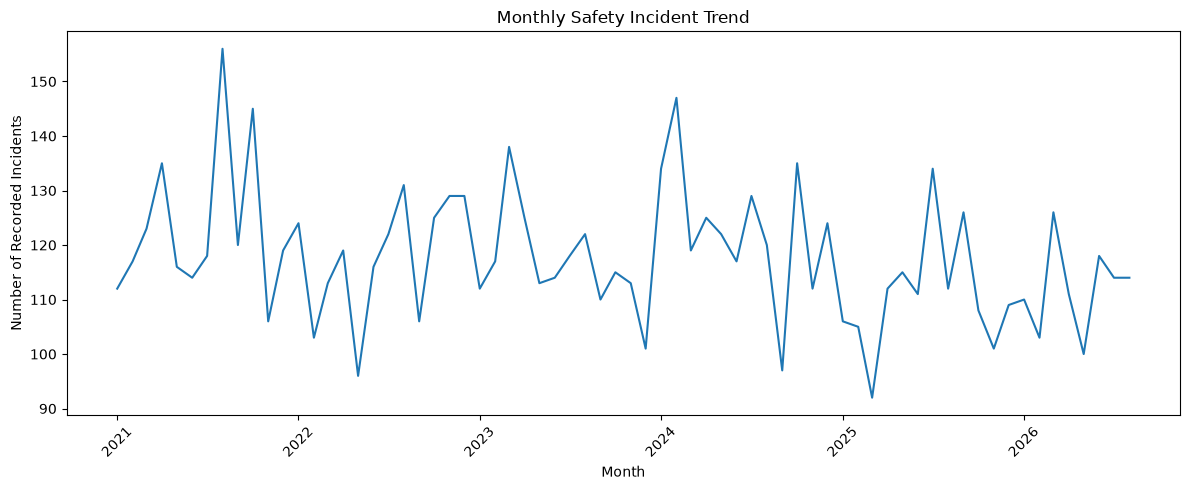

,Incident Count
incident_date,
2021-01-01,112
2021-02-01,117
2021-03-01,123
2021-04-01,135
2021-05-01,116
...,...
2026-04-01,111
2026-05-01,100
2026-06-01,118


In [17]:
monthly_incidents = (
    df_cleaned
    .set_index("incident_date")
    .resample("MS")
    .size()
)

plt.figure(figsize=(12, 5))
plt.plot(monthly_incidents.index, monthly_incidents.values)

plt.title("Monthly Safety Incident Trend")
plt.xlabel("Month")
plt.ylabel("Number of Recorded Incidents")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(monthly_incidents.to_frame("Incident Count"))

Risk Score Statistics


count    8000.000000
mean       41.610238
std        20.654510
min         1.900000
25%        25.000000
50%        39.500000
75%        56.300000
max       100.000000
Name: risk_score, dtype: float64

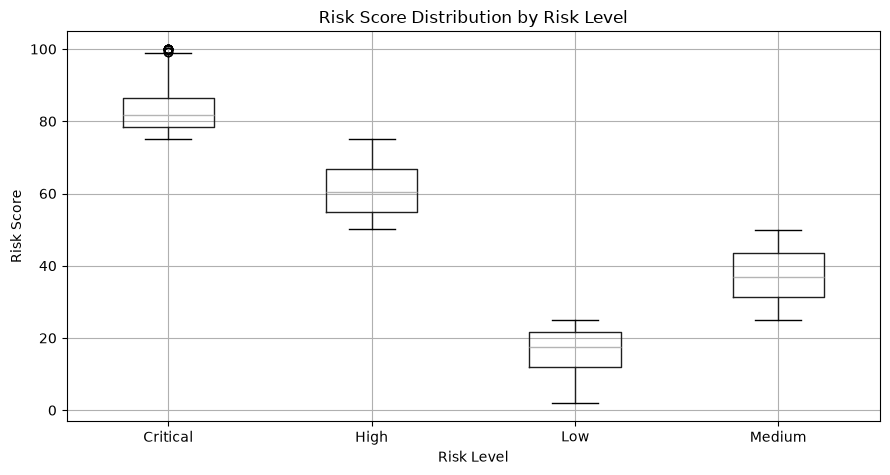

In [18]:
print("Risk Score Statistics")
display(df_cleaned["risk_score"].describe())

df_cleaned.boxplot(
    column="risk_score",
    by="risk_level",
    figsize=(9, 5)
)

plt.title("Risk Score Distribution by Risk Level")
plt.suptitle("")
plt.xlabel("Risk Level")
plt.ylabel("Risk Score")
plt.tight_layout()
plt.show()

In [20]:
print(df.columns.tolist())

['incident_id', 'incident_date', 'incident_time', 'department', 'location', 'shift', 'employee_role', 'experience_level', 'equipment_type', 'equipment_status', 'incident_type', 'hazard_type', 'incident_description', 'injury_type', 'body_part_affected', 'medical_treatment_required', 'root_cause_category', 'root_cause_description', 'contributing_factor_1', 'contributing_factor_2', 'severity_level', 'risk_level', 'risk_score', 'immediate_action', 'corrective_action', 'preventive_action', 'reported_by_role', 'investigation_status', 'incident_status', 'lost_time_days']


In [21]:
# Remove accidental spaces from column names
df.columns = df.columns.str.strip()

# Create clean_description if it doesn't exist
if "clean_description" not in df.columns:
    df["clean_description"] = (
        df["incident_description"]
        .fillna("")
        .astype(str)
        .str.strip()
    )

print("Column ready:", "clean_description" in df.columns)
print(df[["incident_description", "clean_description"]].head())

Column ready: True
                                incident_description  \
0  A process technician came into contact with ca...   
1  At around 5:10 am, a cutting blade on the air-...   
2  A worker was hit by a pallet being moved by a ...   
3  A quality inspector inhaled fumes while cleani...   
4  An assembly operator experienced strain while ...   

                                   clean_description  
0  A process technician came into contact with ca...  
1  At around 5:10 am, a cutting blade on the air-...  
2  A worker was hit by a pallet being moved by a ...  
3  A quality inspector inhaled fumes while cleani...  
4  An assembly operator experienced strain while ...  


In [22]:
X = df["clean_description"].fillna("").astype(str)
y = df["root_cause_category"].astype(str)

# Remove empty descriptions and missing labels
valid = X.str.strip().ne("") & y.str.strip().ne("")
X = X[valid]
y = y[valid]

print("Usable records:", len(X))
print("Root-cause categories:", y.nunique())

Usable records: 8000
Root-cause categories: 15


In [23]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts())

Training records: 6400
Testing records: 1600

Training class distribution:
root_cause_category
Procedure Violation           724
Human Error                   715
Poor Housekeeping             630
Unsafe Working Condition      555
Inadequate Training           535
Fatigue/Workload              454
Poor Maintenance              396
Inadequate Risk Assessment    390
Supervision Failure           361
Design Deficiency             330
Equipment Failure             307
Communication Failure         287
PPE Non-Compliance            282
Environmental Condition       278
Other                         156
Name: count, dtype: int64


In [24]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

model = Pipeline([
    ("tfidf", TfidfVectorizer(
        stop_words="english",
        ngram_range=(1, 2),
        max_features=20000
    )),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ))
])

model.fit(X_train, y_train)

print("NLP model trained successfully!")

NLP model trained successfully!


In [25]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# Predict root causes for test data
y_pred = model.predict(X_test)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0
)

print("MODEL EVALUATION RESULTS")
print("-" * 40)

print(f"Accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Macro F1-score: {macro_f1:.4f}")

print("\nClassification Report:\n")

print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

MODEL EVALUATION RESULTS
----------------------------------------
Accuracy: 0.8313 (83.12%)
Macro F1-score: 0.8272

Classification Report:

                            precision    recall  f1-score   support

     Communication Failure       0.70      0.92      0.80        72
         Design Deficiency       0.90      0.77      0.83        83
   Environmental Condition       0.81      0.90      0.85        70
         Equipment Failure       0.75      0.73      0.74        77
          Fatigue/Workload       0.83      0.90      0.86       113
               Human Error       0.97      0.81      0.88       179
Inadequate Risk Assessment       0.79      0.80      0.80        97
       Inadequate Training       0.79      0.74      0.76       134
                     Other       0.89      0.87      0.88        39
        PPE Non-Compliance       0.84      0.91      0.88        70
         Poor Housekeeping       0.88      0.92      0.90       157
          Poor Maintenance       0.80      

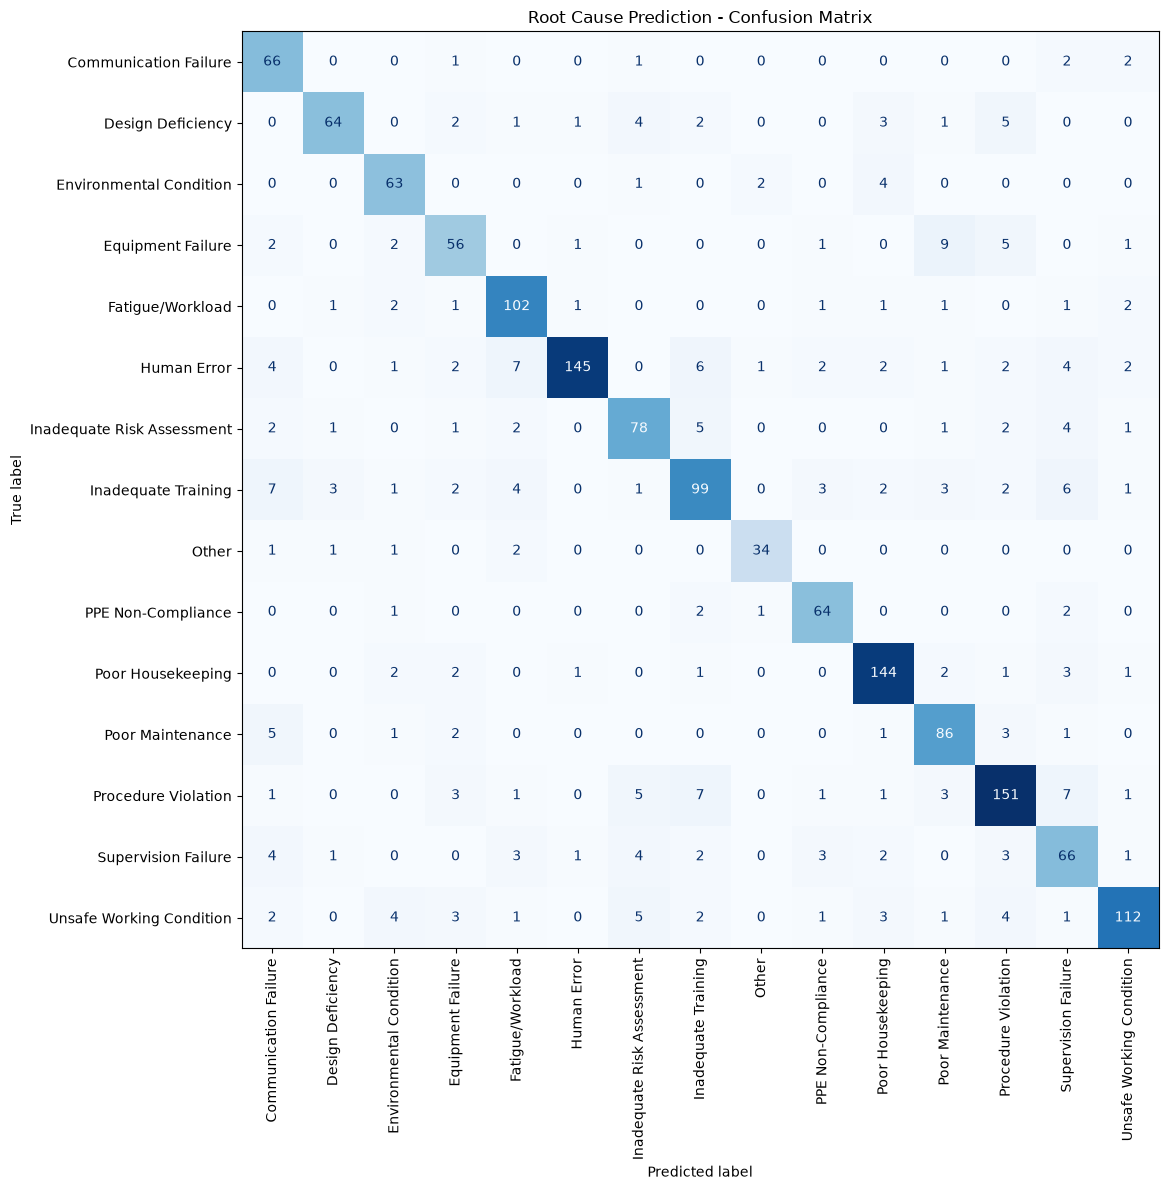

In [26]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(14, 12))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    xticks_rotation=90,
    cmap="Blues",
    ax=ax,
    colorbar=False
)

plt.title("Root Cause Prediction - Confusion Matrix")
plt.tight_layout()
plt.show()

In [27]:
new_incident = [
    "A machine operator suffered an injury after "
    "removing a safety guard while the equipment "
    "was running. The operator had not followed "
    "the required safety procedure."
]

predicted_cause = model.predict(new_incident)

print("Incident Description:")
print(new_incident[0])

print("\nPredicted Root Cause:")
print(predicted_cause[0])

Incident Description:
A machine operator suffered an injury after removing a safety guard while the equipment was running. The operator had not followed the required safety procedure.

Predicted Root Cause:
Procedure Violation


In [28]:
from pathlib import Path
import joblib

# Find the project directory
current = Path.cwd()

if (current / "MODELS").is_dir():
    project_dir = current
elif (current.parent / "MODELS").is_dir():
    project_dir = current.parent
else:
    project_dir = current
    (project_dir / "MODELS").mkdir(exist_ok=True)

# Create the model directory if needed
model_dir = project_dir / "MODELS"
model_dir.mkdir(parents=True, exist_ok=True)

# Save the complete TF-IDF + Logistic Regression pipeline
model_path = model_dir / "safety_root_cause_model.joblib"
joblib.dump(model, model_path)

print("Model saved successfully!")
print("Location:", model_path.resolve())

Model saved successfully!
Location: C:\Users\mohammad rayyan\SAFETY_INCIDENT_NLP\MODELS\safety_root_cause_model.joblib


In [31]:
import joblib
from pathlib import Path

# Locate the saved model automatically
filename = "safe_root_cause_model.joblib"
current = Path.cwd()

possible_paths = [
    current / "MODELS" / filename,
    current.parent / "MODELS" / filename
]

model_path = next(
    (path for path in possible_paths if path.exists()),
    None
)

if model_path is None:
    print("Model file not found.")
    print("Current directory:", current)
    print("Please check the MODELS folder.")
else:
    loaded_model = joblib.load(model_path)
    print("Model loaded successfully!")
    print("Location:", model_path)

Model file not found.
Current directory: C:\Users\mohammad rayyan\SAFETY_INCIDENT_NLP\NOTEBOOK
Please check the MODELS folder.


In [34]:
from pathlib import Path

current = Path.cwd()

print("Current working directory:")
print(current)

print("\nParent directory:")
print(current.parent)

print("\nChecking expected model locations:")

paths = [
    current / "MODELS" / "safe_root_cause_model.joblib",
    current.parent / "MODELS" / "safe_root_cause_model.joblib",
    current.parent.parent / "MODELS" / "safe_root_cause_model.joblib"
]

for path in paths:
    print(path, "->", path.exists())

Current working directory:
C:\Users\mohammad rayyan\SAFETY_INCIDENT_NLP\NOTEBOOK

Parent directory:
C:\Users\mohammad rayyan\SAFETY_INCIDENT_NLP

Checking expected model locations:
C:\Users\mohammad rayyan\SAFETY_INCIDENT_NLP\NOTEBOOK\MODELS\safe_root_cause_model.joblib -> False
C:\Users\mohammad rayyan\SAFETY_INCIDENT_NLP\MODELS\safe_root_cause_model.joblib -> False
C:\Users\mohammad rayyan\MODELS\safe_root_cause_model.joblib -> False


In [35]:
from pathlib import Path
import joblib

project_dir = Path.cwd().parent

matches = list(
    project_dir.rglob("safe_root_cause_model.joblib")
)

if matches:
    model_path = matches[0]
    loaded_model = joblib.load(model_path)

    print("Model loaded successfully!")
    print("Found at:", model_path)
else:
    print("Model not found in:", project_dir)
    print("Check whether Jupyter is using the same project folder "
          "where you saved the model.")

Model not found in: C:\Users\mohammad rayyan\SAFETY_INCIDENT_NLP
Check whether Jupyter is using the same project folder where you saved the model.


In [ ]:
from pathlib import Path

current = Path.cwd()
project_dir = current.parent
models_dir = project_dir / "MODELS"

print("Current directory:", current)
print("Project directory:", project_dir)
print("MODELS folder exists:", models_dir.exists())

if models_dir.exists():
    print("\nFiles inside MODELS:")
    for file in models_dir.iterdir():
        print(repr(file.name))

In [40]:
from pathlib import Path

current = Path.cwd()
project_dir = current.parent
models_dir = project_dir / "MODELS"

print("Current directory:", current)
print("Project directory:", project_dir)
print("MODELS folder exists:", models_dir.exists())

if models_dir.exists():
    print("\nFiles inside MODELS:")
    for file in models_dir.iterdir():
        print(repr(file.name))

Current directory: C:\Users\mohammad rayyan\SAFETY_INCIDENT_NLP\NOTEBOOK
Project directory: C:\Users\mohammad rayyan\SAFETY_INCIDENT_NLP
MODELS folder exists: True

Files inside MODELS:
'.ipynb_checkpoints'
'safety_root_cause_model.joblib'


In [41]:
from pathlib import Path
import joblib

project_dir = Path.cwd().parent

model_path = project_dir / "MODELS" / "safety_root_cause_model.joblib"

print("Model path:", model_path)
print("Model exists:", model_path.exists())

loaded_model = joblib.load(model_path)

print("Model loaded successfully!")

Model path: C:\Users\mohammad rayyan\SAFETY_INCIDENT_NLP\MODELS\safety_root_cause_model.joblib
Model exists: True
Model loaded successfully!


In [42]:
test_incident = [
    "A worker slipped on an oily floor because the area "
    "had not been cleaned or marked with a warning sign."
]

prediction = loaded_model.predict(test_incident)

print("Incident:", test_incident[0])
print("Predicted root cause:", prediction[0])

Incident: A worker slipped on an oily floor because the area had not been cleaned or marked with a warning sign.
Predicted root cause: Poor Housekeeping


In [43]:
test_incidents = [
    "A worker slipped on an oily floor that had not been cleaned.",
    "A machine malfunctioned because a worn component was not replaced.",
    "An employee operated equipment without following safety procedures.",
    "A worker was injured because they had not received proper safety training.",
    "A chemical spill occurred due to a leaking pipe."
]

predictions = loaded_model.predict(test_incidents)

for i, incident in enumerate(test_incidents):
    print(f"\nIncident {i+1}: {incident}")
    print(f"Predicted root cause: {predictions[i]}")


Incident 1: A worker slipped on an oily floor that had not been cleaned.
Predicted root cause: Poor Housekeeping

Incident 2: A machine malfunctioned because a worn component was not replaced.
Predicted root cause: Equipment Failure

Incident 3: An employee operated equipment without following safety procedures.
Predicted root cause: Procedure Violation

Incident 4: A worker was injured because they had not received proper safety training.
Predicted root cause: Inadequate Training

Incident 5: A chemical spill occurred due to a leaking pipe.
Predicted root cause: Poor Maintenance


In [44]:
print("X_test available:", "X_test" in globals())
print("y_test available:", "y_test" in globals())

X_test available: True
y_test available: True


In [45]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

y_pred = loaded_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.83125

Classification Report:
                            precision    recall  f1-score   support

     Communication Failure       0.70      0.92      0.80        72
         Design Deficiency       0.90      0.77      0.83        83
   Environmental Condition       0.81      0.90      0.85        70
         Equipment Failure       0.75      0.73      0.74        77
          Fatigue/Workload       0.83      0.90      0.86       113
               Human Error       0.97      0.81      0.88       179
Inadequate Risk Assessment       0.79      0.80      0.80        97
       Inadequate Training       0.79      0.74      0.76       134
                     Other       0.89      0.87      0.88        39
        PPE Non-Compliance       0.84      0.91      0.88        70
         Poor Housekeeping       0.88      0.92      0.90       157
          Poor Maintenance       0.80      0.87      0.83        99
       Procedure Violation       0.85      0.83      0.84       181
     

In [46]:
variables_to_check = [
    "df_cleaned",
    "X",
    "y",
    "X_train",
    "X_test",
    "y_train",
    "y_test",
    "model",
    "loaded_model",
    "y_pred"
]

for name in variables_to_check:
    print(f"{name}: {'Available' if name in globals() else 'Not available'}")

df_cleaned: Available
X: Available
y: Available
X_train: Available
X_test: Available
y_train: Available
y_test: Available
model: Available
loaded_model: Available
y_pred: Available


In [47]:
from sklearn.metrics import accuracy_score, f1_score

y_test_pred = loaded_model.predict(X_test)

print("Test records:", len(X_test))
print("Accuracy:", round(accuracy_score(y_test, y_test_pred), 4))
print("Macro F1:", round(
    f1_score(y_test, y_test_pred, average="macro"), 4
))

Test records: 1600
Accuracy: 0.8313
Macro F1: 0.8272


In [48]:
import pandas as pd

error_analysis = pd.DataFrame({
    "Incident Description": X_test.reset_index(drop=True),
    "Actual Root Cause": y_test.reset_index(drop=True),
    "Predicted Root Cause": y_test_pred
})

errors = error_analysis[
    error_analysis["Actual Root Cause"] !=
    error_analysis["Predicted Root Cause"]
]

print("Total incorrect predictions:", len(errors))
print("\nSample incorrect predictions:")

display(errors.head(10))

Total incorrect predictions: 270

Sample incorrect predictions:


,Incident Description,Actual Root Cause,Predicted Root Cause
15,"At around 1:27 pm, a forklift truck struck a p...",Inadequate Risk Assessment,Supervision Failure
21,A boiler operator tripped over a raised drain ...,Fatigue/Workload,Poor Housekeeping
24,A loader was knocked down by a forklift at the...,Poor Maintenance,Equipment Failure
27,The production helper was struck by the load o...,Unsafe Working Condition,Procedure Violation
32,A mechanical fitter was drawn into the rollers...,Supervision Failure,Procedure Violation
37,"While sorting incoming goods, a stores supervi...",Human Error,Fatigue/Workload
43,Metal chips ejected from the motor hit a maint...,Poor Maintenance,Procedure Violation
45,A shift chemist suffered irritation after hand...,Procedure Violation,Inadequate Risk Assessment
47,While handling incoming goods in the plant flo...,Other,Fatigue/Workload
49,"While the morning shift was in progress, a sta...",Inadequate Training,Inadequate Risk Assessment


In [49]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, classification_report

svm_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        stop_words="english",
        ngram_range=(1, 2),
        max_features=20000
    )),
    ("classifier", LinearSVC(
        class_weight="balanced",
        random_state=42
    ))
])

svm_model.fit(X_train, y_train)

svm_pred = svm_model.predict(X_test)

print("MODEL COMPARISON")
print("-" * 35)

print("Logistic Regression Accuracy:",
      round(accuracy_score(y_test, y_test_pred), 4))

print("Logistic Regression Macro F1:",
      round(f1_score(y_test, y_test_pred, average="macro"), 4))

print()

print("LinearSVC Accuracy:",
      round(accuracy_score(y_test, svm_pred), 4))

print("LinearSVC Macro F1:",
      round(f1_score(y_test, svm_pred, average="macro"), 4))

MODEL COMPARISON
-----------------------------------
Logistic Regression Accuracy: 0.8313
Logistic Regression Macro F1: 0.8272

LinearSVC Accuracy: 0.8494
LinearSVC Macro F1: 0.8423


In [50]:
from sklearn.metrics import classification_report

print(classification_report(y_test, svm_pred, digits=3))

                            precision    recall  f1-score   support

     Communication Failure      0.739     0.903     0.812        72
         Design Deficiency      0.905     0.807     0.854        83
   Environmental Condition      0.827     0.886     0.855        70
         Equipment Failure      0.949     0.727     0.824        77
          Fatigue/Workload      0.836     0.903     0.868       113
               Human Error      0.951     0.860     0.903       179
Inadequate Risk Assessment      0.812     0.845     0.828        97
       Inadequate Training      0.791     0.791     0.791       134
                     Other      0.829     0.872     0.850        39
        PPE Non-Compliance      0.851     0.900     0.875        70
         Poor Housekeeping      0.907     0.930     0.918       157
          Poor Maintenance      0.781     0.899     0.836        99
       Procedure Violation      0.848     0.895     0.871       181
       Supervision Failure      0.709     0.678

In [51]:
from pathlib import Path
import joblib

current = Path.cwd()
project_root = next(
    (p for p in [current, *current.parents]
     if (p / "MODELS").is_dir()),
    None
)

if project_root is None:
    raise FileNotFoundError(
        "Could not find the MODELS folder. Check your project path."
    )

model_path = project_root / "MODELS" / "safety_root_cause_model.joblib"

if model_path.exists():
    backup_path = project_root / "MODELS" / "logistic_regression_backup.joblib"
    if not backup_path.exists():
        joblib.dump(loaded_model, backup_path)

joblib.dump(svm_model, model_path)

final_model = joblib.load(model_path)
test_prediction = final_model.predict([
    "An employee slipped on an oily floor near the production area."
])

print("Saved model:", model_path)
print("Test prediction:", test_prediction[0])

Saved model: C:\Users\mohammad rayyan\SAFETY_INCIDENT_NLP\MODELS\safety_root_cause_model.joblib
Test prediction: Poor Housekeeping


In [52]:
from pathlib import Path

current = Path.cwd()

project_root = next(
    (
        p for p in [current, *current.parents]
        if (p / "MODELS").is_dir()
    ),
    None
)

if project_root is None:
    raise FileNotFoundError("Project folder not found.")

processed_dir = project_root / "DATA" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

csv_path = processed_dir / "safety_incidents_cleaned.csv"

df_cleaned.to_csv(csv_path, index=False)

print("Dataset saved successfully!")
print("Location:", csv_path)
print("Rows:", len(df_cleaned))
print("Columns:", len(df_cleaned.columns))

Dataset saved successfully!
Location: C:\Users\mohammad rayyan\SAFETY_INCIDENT_NLP\DATA\processed\safety_incidents_cleaned.csv
Rows: 8000
Columns: 31


In [2]:
print("Model type:", type(final_model))

print("\nModel details:")
print(final_model)

print("\nAvailable classes:")
print(final_model.classes_)

NameError: name 'final_model' is not defined

In [3]:
from pathlib import Path
import joblib

current = Path.cwd()

project_root = next(
    (p for p in [current, *current.parents]
     if (p / "MODELS").is_dir()),
    None
)

if project_root is None:
    raise FileNotFoundError("MODELS folder not found")

model_path = (
    project_root / "MODELS" /
    "safety_root_cause_model.joblib"
)

final_model = joblib.load(model_path)

print("Model loaded successfully!")
print("Model type:", type(final_model))
print("Model details:", final_model)
print("Available classes:", final_model.classes_)

Model loaded successfully!
Model type: <class 'sklearn.pipeline.Pipeline'>
Model details: Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_features=20000, ngram_range=(1, 2),
                                 stop_words='english')),
                ('classifier',
                 LinearSVC(class_weight='balanced', random_state=42))])
Available classes: ['Communication Failure' 'Design Deficiency' 'Environmental Condition'
 'Equipment Failure' 'Fatigue/Workload' 'Human Error'
 'Inadequate Risk Assessment' 'Inadequate Training' 'Other'
 'PPE Non-Compliance' 'Poor Housekeeping' 'Poor Maintenance'
 'Procedure Violation' 'Supervision Failure' 'Unsafe Working Condition']


In [4]:
test_cases = [
    "An employee slipped on an oily floor near the production area.",
    "Worker was injured because safety gloves were not used.",
    "Machine stopped working due to mechanical failure.",
    "Employee was not properly trained to operate the equipment.",
    "Supervisor failed to communicate safety instructions."
]

for text in test_cases:
    prediction = final_model.predict([text])[0]

    print("Incident:", text)
    print("Predicted Root Cause:", prediction)
    print("-" * 70)

Incident: An employee slipped on an oily floor near the production area.
Predicted Root Cause: Poor Housekeeping
----------------------------------------------------------------------
Incident: Worker was injured because safety gloves were not used.
Predicted Root Cause: PPE Non-Compliance
----------------------------------------------------------------------
Incident: Machine stopped working due to mechanical failure.
Predicted Root Cause: Procedure Violation
----------------------------------------------------------------------
Incident: Employee was not properly trained to operate the equipment.
Predicted Root Cause: Inadequate Training
----------------------------------------------------------------------
Incident: Supervisor failed to communicate safety instructions.
Predicted Root Cause: Equipment Failure
----------------------------------------------------------------------


In [1]:
import pandas as pd
from pathlib import Path

PROJECT_ROOT = Path(r"C:\Users\mohammad rayyan\SAFETY_INCIDENT_NLP")

DATA_PATH = PROJECT_ROOT / "DATA" / "processed" / "safety_incidents_cleaned.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset Shape:", df.shape)

display(df.head())

Dataset Shape: (8000, 31)


,incident_id,incident_date,incident_time,department,location,shift,employee_role,experience_level,equipment_type,equipment_status,...,risk_level,risk_score,immediate_action,corrective_action,preventive_action,reported_by_role,investigation_status,incident_status,lost_time_days,clean_description
0,INC-2021-00001,2021-01-01,00:09,Chemical Processing,Effluent Treatment Plant,Night,Process Technician,1-3 years,Chemical Storage Cabinet,Damaged,...,High,61.9,"Employee moved to fresh air, contaminated clot...",Review the chemical transfer and handling meth...,"Set up PPE compliance audits, stock availabili...",Shift Manager,Completed,Closed,8,a process technician came into contact with ca...
1,INC-2021-00002,2021-01-01,05:10,Assembly,Assembly Line B,Night,Line Supervisor,3-7 years,Pneumatic Tool,Operational,...,High,52.6,Machine stopped and isolated; injured employee...,"Inspect the air-powered driver, repair or repl...","Implement permit-to-work audits, lock-out/tag-...",Supervisor,Completed,Closed,17,at around 5 10 am a cutting blade on the air p...
2,INC-2021-00003,2021-01-01,07:25,Production,Machining Bay,Morning,Production Technician,More than 7 years,Forklift,Operational,...,Medium,27.6,Area secured and injured employee sent to the ...,"Secure loose material, install a barrier aroun...",Standardise the shift handover format and use ...,Supervisor,Completed,Closed,0,a worker was hit by a pallet being moved by a ...
3,INC-2021-00004,2021-01-01,08:52,Quality Control & Laboratory,Incoming Inspection,Morning,Quality Inspector,3-7 years,Fume Hood,Operational,...,Medium,27.8,"Employee moved to fresh air, contaminated clot...",Review the chemical transfer and handling meth...,Standardise the shift handover format and use ...,Supervisor,Completed,Closed,0,a quality inspector inhaled fumes while cleani...
4,INC-2021-00005,2021-01-01,09:26,Assembly,Sub-assembly Area,Morning,Assembly Operator,More than 7 years,Not Applicable,Not Applicable,...,Low,19.3,Task rotated and injured employee sent for med...,"Adjust the workstation layout, provide adjusta...",Include HSE review at the design and modificat...,Co-worker,Completed,Closed,1,an assembly operator experienced strain while ...


In [2]:
import pandas as pd
import numpy as np
import joblib
from pathlib import Path
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

text_candidates = [
    "incident_description",
    "ACCIDENT_DETAILS",
    "FAILURE_DETAILS",
    "CAUSE_DETAILS",
    "incident_details",
    "description"
]

text_columns = [col for col in text_candidates if col in df.columns]

print("Selected columns:", text_columns)

if not text_columns:
    raise ValueError("No suitable text columns found.")

history = df.copy()

history["similarity_text"] = (
    history[text_columns]
    .fillna("")
    .astype(str)
    .agg(" ".join, axis=1)
    .str.strip()
)

history = history[history["similarity_text"].str.len() > 0].copy()

vectorizer = TfidfVectorizer(
    max_features=20000,
    stop_words="english",
    ngram_range=(1, 2)
)

tfidf_matrix = vectorizer.fit_transform(history["similarity_text"])

print("Historical incidents:", len(history))
print("Matrix shape:", tfidf_matrix.shape)

Selected columns: ['incident_description']
Historical incidents: 8000
Matrix shape: (8000, 19946)


In [3]:
def find_similar_incidents(new_report, top_n=5):
    query_vector = vectorizer.transform([new_report])

    similarity_scores = cosine_similarity(
        query_vector,
        tfidf_matrix
    ).flatten()

    top_indices = np.argsort(similarity_scores)[::-1][:top_n]

    results = history.iloc[top_indices].copy()
    results["similarity_score"] = (
        similarity_scores[top_indices] * 100
    ).round(2)

    return results.sort_values(
        "similarity_score",
        ascending=False
    )

In [4]:
test_report = """
An employee slipped on an oily floor near the production area
due to oil leakage. The floor was not cleaned properly,
creating an unsafe working environment.
"""

similar_incidents = find_similar_incidents(test_report, top_n=5)

display(similar_incidents)

,incident_id,incident_date,incident_time,department,location,shift,employee_role,experience_level,equipment_type,equipment_status,...,immediate_action,corrective_action,preventive_action,reported_by_role,investigation_status,incident_status,lost_time_days,clean_description,similarity_text,similarity_score
3325,INC-2023-00432,2023-04-14,16:16,Production,Production Line 2,Evening,Machine Operator,1-3 years,Not Applicable,Not Applicable,...,Hazard made safe on the spot and the near miss...,Correct the unsafe condition identified and co...,Encourage incident and near-miss reporting to ...,Co-worker,Not Required,Closed,0,a machine operator nearly slipped on a wet flo...,A machine operator nearly slipped on a wet flo...,26.57
316,INC-2021-00317,2021-03-24,07:40,Production,Production Line 2,Morning,Production Technician,More than 7 years,Not Applicable,Not Applicable,...,Hazard made safe on the spot and the near miss...,Correct the unsafe condition identified and co...,Perform regular workplace inspections and clos...,Co-worker,Completed,Closed,0,at around 7 40 am an employee nearly slipped o...,"At around 7:40 am, an employee nearly slipped ...",20.00
1832,INC-2022-00352,2022-04-04,02:38,Production,Production Line 1,Night,CNC Operator,More than 7 years,Not Applicable,Not Applicable,...,"Area barricaded with warning signs, floor clea...","Clean the affected floor, repair the source of...",Define supervisor span of control and introduc...,Supervisor,Completed,Closed,0,a cnc operator lost footing on the wet floor n...,A CNC operator lost footing on the wet floor n...,19.17
5095,INC-2024-00804,2024-07-10,11:21,Production,Production Line 2,Morning,Machine Operator,More than 7 years,Not Applicable,Not Applicable,...,Injured employee given first aid and area cord...,"Clean the affected floor, repair the source of...","Monitor overtime limits, schedule adequate res...",Safety Officer,Completed,Closed,0,a machine operator lost footing on the wet flo...,A machine operator lost footing on the wet flo...,18.97
7882,INC-2026-00779,2026-07-30,16:02,Warehouse & Logistics,Despatch Area,Evening,Warehouse Associate,Less than 1 year,Dock Leveler,Operational,...,Injured employee given first aid and area cord...,"Clean and dry the floor, mark the wet area and...",Schedule daily housekeeping inspections and 5S...,Supervisor,Under Investigation,Open,6,in the despatch area oil dripping from the loa...,"In the Despatch Area, oil dripping from the lo...",18.79


In [5]:
MODEL_DIR = Path(
    r"C:\Users\mohammad rayyan\SAFETY_INCIDENT_NLP\MODELS"
)

MODEL_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(
    {
        "vectorizer": vectorizer,
        "tfidf_matrix": tfidf_matrix,
        "history": history
    },
    MODEL_DIR / "similar_incident_engine.joblib"
)

print("Model saved successfully!")

Model saved successfully!


In [6]:
import joblib
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

engine_path = MODEL_DIR / "similar_incident_engine.joblib"

engine = joblib.load(engine_path)

loaded_vectorizer = engine["vectorizer"]
loaded_matrix = engine["tfidf_matrix"]
loaded_history = engine["history"]

def get_similar_incidents(report, top_n=5):
    query = loaded_vectorizer.transform([report])
    scores = cosine_similarity(query, loaded_matrix).flatten()
    indices = np.argsort(scores)[::-1][:top_n]

    results = loaded_history.iloc[indices].copy()
    results["similarity_score"] = (scores[indices] * 100).round(2)

    return results.sort_values("similarity_score", ascending=False)

test_result = get_similar_incidents(test_report)

display(test_result)

,incident_id,incident_date,incident_time,department,location,shift,employee_role,experience_level,equipment_type,equipment_status,...,immediate_action,corrective_action,preventive_action,reported_by_role,investigation_status,incident_status,lost_time_days,clean_description,similarity_text,similarity_score
3325,INC-2023-00432,2023-04-14,16:16,Production,Production Line 2,Evening,Machine Operator,1-3 years,Not Applicable,Not Applicable,...,Hazard made safe on the spot and the near miss...,Correct the unsafe condition identified and co...,Encourage incident and near-miss reporting to ...,Co-worker,Not Required,Closed,0,a machine operator nearly slipped on a wet flo...,A machine operator nearly slipped on a wet flo...,26.57
316,INC-2021-00317,2021-03-24,07:40,Production,Production Line 2,Morning,Production Technician,More than 7 years,Not Applicable,Not Applicable,...,Hazard made safe on the spot and the near miss...,Correct the unsafe condition identified and co...,Perform regular workplace inspections and clos...,Co-worker,Completed,Closed,0,at around 7 40 am an employee nearly slipped o...,"At around 7:40 am, an employee nearly slipped ...",20.00
1832,INC-2022-00352,2022-04-04,02:38,Production,Production Line 1,Night,CNC Operator,More than 7 years,Not Applicable,Not Applicable,...,"Area barricaded with warning signs, floor clea...","Clean the affected floor, repair the source of...",Define supervisor span of control and introduc...,Supervisor,Completed,Closed,0,a cnc operator lost footing on the wet floor n...,A CNC operator lost footing on the wet floor n...,19.17
5095,INC-2024-00804,2024-07-10,11:21,Production,Production Line 2,Morning,Machine Operator,More than 7 years,Not Applicable,Not Applicable,...,Injured employee given first aid and area cord...,"Clean the affected floor, repair the source of...","Monitor overtime limits, schedule adequate res...",Safety Officer,Completed,Closed,0,a machine operator lost footing on the wet flo...,A machine operator lost footing on the wet flo...,18.97
7882,INC-2026-00779,2026-07-30,16:02,Warehouse & Logistics,Despatch Area,Evening,Warehouse Associate,Less than 1 year,Dock Leveler,Operational,...,Injured employee given first aid and area cord...,"Clean and dry the floor, mark the wet area and...",Schedule daily housekeeping inspections and 5S...,Supervisor,Under Investigation,Open,6,in the despatch area oil dripping from the loa...,"In the Despatch Area, oil dripping from the lo...",18.79


In [7]:
display_columns = [
    "incident_id",
    "incident_date",
    "department",
    "location",
    "equipment_type",
    "root_cause_category",
    "similarity_score"
]

available_columns = [
    col for col in display_columns
    if col in test_result.columns
]

display(test_result[available_columns].reset_index(drop=True))

,incident_id,incident_date,department,location,equipment_type,root_cause_category,similarity_score
0,INC-2023-00432,2023-04-14,Production,Production Line 2,Not Applicable,Other,26.57
1,INC-2021-00317,2021-03-24,Production,Production Line 2,Not Applicable,Unsafe Working Condition,20.00
2,INC-2022-00352,2022-04-04,Production,Production Line 1,Not Applicable,Supervision Failure,19.17
3,INC-2024-00804,2024-07-10,Production,Production Line 2,Not Applicable,Fatigue/Workload,18.97
4,INC-2026-00779,2026-07-30,Warehouse & Logistics,Despatch Area,Dock Leveler,Poor Housekeeping,18.79


In [8]:
print("Average Similarity:",
      round(test_result["similarity_score"].mean(), 2), "%")

print("Highest Similarity:",
      round(test_result["similarity_score"].max(), 2), "%")

Average Similarity: 20.7 %
Highest Similarity: 26.57 %


In [9]:
print("TEXT COLUMNS USED:")
print(text_columns)

for i, (_, row) in enumerate(test_result.iterrows(), 1):
    print(f"\nINCIDENT {i}")
    print("ID:", row.get("incident_id"))
    print("Similarity:", row["similarity_score"], "%")
    print("Root Cause:", row.get("root_cause_category"))
    print("Description:", row["similarity_text"][:600])

TEXT COLUMNS USED:
['incident_description']

INCIDENT 1
ID: INC-2023-00432
Similarity: 26.57 %
Root Cause: Other
Description: A machine operator nearly slipped on a wet floor near the production line 2 but caught the handrail

INCIDENT 2
ID: INC-2021-00317
Similarity: 20.0 %
Root Cause: Unsafe Working Condition
Description: At around 7:40 am, an employee nearly slipped on a wet floor near the production line 2 but caught the handrail. The stacked material was leaning and not secured. Fortunately there were no injuries.

INCIDENT 3
ID: INC-2022-00352
Similarity: 19.17 %
Root Cause: Supervision Failure
Description: A CNC operator lost footing on the wet floor near the production line 1 entrance where rainwater had been tracked in. No supervisor was present in the area at the time.

INCIDENT 4
ID: INC-2024-00804
Similarity: 18.97 %
Root Cause: Fatigue/Workload
Description: A machine operator lost footing on the wet floor near the production line 2 entrance where rainwater had been tracked

In [10]:
hazard_synonyms = {
    "oil": ["oily", "leakage", "leaking", "dripping", "spill", "slick"],
    "floor": ["ground", "surface", "slippery", "wet"],
    "cleaning": ["cleaned", "uncleaned", "residue", "housekeeping"],
    "slip": ["slipped", "slipping", "slippery", "lost footing"],
    "hazard": ["unsafe", "dangerous", "risk", "unmarked"]
}

def expand_query(report):
    words = report.lower().split()
    expanded = [report]

    for key, synonyms in hazard_synonyms.items():
        if key in report.lower():
            expanded.append(" ".join(synonyms))

    return " ".join(expanded)


def get_similar_incidents(report, top_n=5):
    expanded_report = expand_query(report)

    query = loaded_vectorizer.transform([expanded_report])

    scores = cosine_similarity(
        query,
        loaded_matrix
    ).flatten()

    indices = np.argsort(scores)[::-1][:top_n]

    results = loaded_history.iloc[indices].copy()
    results["similarity_score"] = (scores[indices] * 100).round(2)

    return results.sort_values(
        "similarity_score",
        ascending=False
    )

In [11]:
test_result = get_similar_incidents(test_report, top_n=5)

display(
    test_result[
        [
            "incident_id",
            "incident_date",
            "location",
            "root_cause_category",
            "similarity_score"
        ]
    ].reset_index(drop=True)
)

,incident_id,incident_date,location,root_cause_category,similarity_score
0,INC-2023-00432,2023-04-14,Production Line 2,Other,22.14
1,INC-2022-00352,2022-04-04,Production Line 1,Supervision Failure,21.88
2,INC-2024-00804,2024-07-10,Production Line 2,Fatigue/Workload,21.50
3,INC-2023-00503,2023-05-02,Plant Floor,PPE Non-Compliance,18.37
4,INC-2026-00779,2026-07-30,Despatch Area,Poor Housekeeping,17.93


In [12]:
joblib.dump(
    {
        "vectorizer": loaded_vectorizer,
        "tfidf_matrix": loaded_matrix,
        "history": loaded_history,
        "hazard_synonyms": hazard_synonyms
    },
    MODEL_DIR / "similar_incident_engine.joblib"
)

print("Improved similarity engine saved successfully!")

Improved similarity engine saved successfully!


In [13]:
print(df["risk_level"].value_counts(dropna=False))

print("\nPercentage Distribution:")
display(
    (df["risk_level"].value_counts(normalize=True) * 100).round(2)
)

risk_level
Medium      3323
High        2109
Low         2009
Critical     559
Name: count, dtype: int64

Percentage Distribution:


risk_level
Medium      41.54
High        26.36
Low         25.11
Critical     6.99
Name: proportion, dtype: float64

In [14]:
risk_columns = [
    col for col in df.columns
    if any(word in col.lower() for word in [
        "risk", "severity", "score", "incident", "description"
    ])
]

for col in risk_columns:
    print(f"\n{col}")
    print(df[col].dropna().head(3).tolist())


incident_id
['INC-2021-00001', 'INC-2021-00002', 'INC-2021-00003']

incident_date
['2021-01-01', '2021-01-01', '2021-01-01']

incident_time
['00:09', '05:10', '07:25']

incident_type
['Chemical Exposure', 'Machine Injury', 'Struck By Object']

incident_description
['A process technician came into contact with caustic solution during sampling at the chemical storage cabinet. She was not wearing the required chemical-resistant gloves. She was referred to a specialist for an inhalation injury and could not perform normal duties for weeks.', 'At around 5:10 am, a cutting blade on the air-powered driver sliced the line supervisor while he was changing the accessory. The guard had been removed and the machine was left running while he cleaned it. He needed treatment at a nearby hospital for a crush injury to his arm and lost working days.', 'A worker was hit by a pallet being moved by a colleague near the forklift. The container was not labelled and he did not know what it held. The team le

In [15]:
import pandas as pd
import numpy as np
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score

risk_df = df.copy()

risk_df = risk_df.dropna(subset=["risk_level"])

risk_df["clean_description"] = (
    risk_df["clean_description"]
    .fillna("")
    .astype(str)
)

categorical_candidates = [
    "incident_type",
    "department",
    "location",
    "shift",
    "employee_role",
    "experience_level",
    "equipment_type",
    "equipment_status"
]

categorical_features = [
    col for col in categorical_candidates
    if col in risk_df.columns
]

X = risk_df[["clean_description"] + categorical_features]
y = risk_df["risk_level"].astype(str)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "text",
            TfidfVectorizer(
                max_features=15000,
                ngram_range=(1, 2),
                stop_words="english",
                sublinear_tf=True
            ),
            "clean_description"
        ),
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
                ("encoder", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categorical_features
        )
    ]
)

risk_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

risk_model.fit(X_train, y_train)

y_pred = risk_model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("Macro F1:", round(f1_score(y_test, y_pred, average="macro") * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred, labels=risk_model.classes_))

print("\nFeatures used:", list(X.columns))
print("\nClasses:", risk_model.classes_)

Accuracy: 63.31 %
Macro F1: 61.33 %

Classification Report:
              precision    recall  f1-score   support

    Critical       0.43      0.64      0.52       112
        High       0.60      0.58      0.59       422
         Low       0.67      0.79      0.72       402
      Medium       0.69      0.57      0.63       664

    accuracy                           0.63      1600
   macro avg       0.60      0.65      0.61      1600
weighted avg       0.64      0.63      0.63      1600


Confusion Matrix:
[[ 72  37   0   3]
 [ 76 245  13  88]
 [  1   7 316  78]
 [ 18 121 145 380]]

Features used: ['clean_description', 'incident_type', 'department', 'location', 'shift', 'employee_role', 'experience_level', 'equipment_type', 'equipment_status']

Classes: ['Critical' 'High' 'Low' 'Medium']


In [16]:
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

risk_svc = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LinearSVC(
        C=1.0,
        class_weight="balanced",
        random_state=42,
        max_iter=5000
    ))
])

risk_svc.fit(X_train, y_train)

svc_pred = risk_svc.predict(X_test)

print("Linear SVC Accuracy:", round(accuracy_score(y_test, svc_pred) * 100, 2), "%")
print("Linear SVC Macro F1:", round(f1_score(y_test, svc_pred, average="macro") * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, svc_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, svc_pred, labels=risk_svc.classes_))

Linear SVC Accuracy: 64.06 %
Linear SVC Macro F1: 62.06 %

Classification Report:
              precision    recall  f1-score   support

    Critical       0.54      0.53      0.53       112
        High       0.61      0.61      0.61       422
         Low       0.67      0.73      0.70       402
      Medium       0.66      0.62      0.64       664

    accuracy                           0.64      1600
   macro avg       0.62      0.62      0.62      1600
weighted avg       0.64      0.64      0.64      1600


Confusion Matrix:
[[ 59  49   0   4]
 [ 44 257  12 109]
 [  1   3 294 104]
 [  6 112 131 415]]


In [17]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score, classification_report

risk_rf = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        min_samples_split=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

risk_rf.fit(X_train, y_train)

rf_pred = risk_rf.predict(X_test)

print("Random Forest Accuracy:", round(accuracy_score(y_test, rf_pred) * 100, 2), "%")
print("Random Forest Macro F1:", round(f1_score(y_test, rf_pred, average="macro") * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

Random Forest Accuracy: 62.88 %
Random Forest Macro F1: 61.92 %

Classification Report:
              precision    recall  f1-score   support

    Critical       0.51      0.66      0.58       112
        High       0.62      0.60      0.61       422
         Low       0.64      0.67      0.66       402
      Medium       0.65      0.62      0.63       664

    accuracy                           0.63      1600
   macro avg       0.61      0.64      0.62      1600
weighted avg       0.63      0.63      0.63      1600



In [18]:
import importlib.util

print(importlib.util.find_spec("catboost"))

None


In [19]:
%pip install catboost


   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 1.0/101.7 MB 18.1 MB/s eta 0:00:06
   - -------------------------------------- 4.7/101.7 MB 17.9 MB/s eta 0:00:06
   -- ------------------------------------- 7.6/101.7 MB 15.5 MB/s eta 0:00:07
   ---- ----------------------------------- 10.5/101.7 MB 14.6 MB/s eta 0:00:07
   ----- ---------------------------------- 12.8/101.7 MB 13.9 MB/s eta 0:00:07
   ------ --------------------------------- 15.5/101.7 MB 13.6 MB/s eta 0:00:07
   ------- -------------------------------- 18.4/101.7 MB 13.5 MB/s eta 0:00:07
   -------- ------------------------------- 21.2/101.7 MB 13.4 MB/s eta 0:00:07
   --------- ------------------------------ 23.9/101.7 MB 13.3 MB/s eta 0:00:06
   ---------- ----------------------------- 26.7/101.7 MB 13.3 MB/s eta 0:00:06
   ----------- ---------------------------- 29.6/101.7 MB 13.2 MB/s eta 0:00:06
   ------------ --------------------------- 32.0/101


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [20]:
from catboost import CatBoostClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

cat_features = list(range(1, X_train.shape[1]))

risk_catboost = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", CatBoostClassifier(
        iterations=500,
        depth=6,
        learning_rate=0.05,
        loss_function="MultiClass",
        auto_class_weights="Balanced",
        verbose=100,
        random_seed=42,
        allow_writing_files=False
    ))
])

In [21]:
X_cat = X.copy()

for col in categorical_features:
    X_cat[col] = X_cat[col].fillna("Unknown").astype(str)

X_cat["clean_description"] = X_cat["clean_description"].fillna("")

X_cat_train, X_cat_test, y_cat_train, y_cat_test = train_test_split(
    X_cat,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

cat_model = CatBoostClassifier(
    iterations=500,
    depth=6,
    learning_rate=0.05,
    loss_function="MultiClass",
    auto_class_weights="Balanced",
    verbose=100,
    random_seed=42,
    allow_writing_files=False
)

cat_model.fit(
    X_cat_train,
    y_cat_train,
    cat_features=categorical_features
)

cat_pred = cat_model.predict(X_cat_test).flatten()

print("CatBoost Accuracy:", round(accuracy_score(y_cat_test, cat_pred) * 100, 2), "%")
print("CatBoost Macro F1:", round(f1_score(y_cat_test, cat_pred, average="macro") * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_cat_test, cat_pred))

CatBoostError: Bad value for num_feature[non_default_doc_idx=0,feature_idx=0]="in the production line 2 the machine operator collapsed while carrying out a task next to the injection moulding machine in the production line 2 no warning sign or barricade had been placed around the area she needed treatment at a nearby hospital for a case of heat stroke and lost working days": Cannot convert 'in the production line 2 the machine operator collapsed while carrying out a task next to the injection moulding machine in the production line 2 no warning sign or barricade had been placed around the area she needed treatment at a nearby hospital for a case of heat stroke and lost working days' to float

In [22]:
from catboost import CatBoostClassifier

text_features = ["clean_description"]

cat_model = CatBoostClassifier(
    iterations=500,
    depth=6,
    learning_rate=0.05,
    loss_function="MultiClass",
    auto_class_weights="Balanced",
    verbose=100,
    random_seed=42,
    allow_writing_files=False
)

cat_model.fit(
    X_cat_train,
    y_cat_train,
    cat_features=categorical_features,
    text_features=text_features
)

0:	learn: 1.3424033	total: 531ms	remaining: 4m 24s
100:	learn: 0.7834958	total: 39.5s	remaining: 2m 36s
200:	learn: 0.6962781	total: 1m 18s	remaining: 1m 57s
300:	learn: 0.6366390	total: 1m 58s	remaining: 1m 18s
400:	learn: 0.5968265	total: 2m 38s	remaining: 39.2s
499:	learn: 0.5643668	total: 3m 18s	remaining: 0us


CatBoostClassifier(allow_writing_files=False, auto_class_weights='Balanced', depth=6, iterations=500, learning_rate=0.05, loss_function='MultiClass', random_seed=42, verbose=100)

In [23]:
cat_pred = cat_model.predict(X_cat_test).flatten()

print("CatBoost Accuracy:", round(accuracy_score(y_cat_test, cat_pred) * 100, 2), "%")
print("CatBoost Macro F1:", round(f1_score(y_cat_test, cat_pred, average="macro") * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_cat_test, cat_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_cat_test, cat_pred))

CatBoost Accuracy: 62.88 %
CatBoost Macro F1: 62.62 %

Classification Report:
              precision    recall  f1-score   support

    Critical       0.52      0.71      0.60       112
        High       0.60      0.65      0.62       422
         Low       0.63      0.78      0.70       402
      Medium       0.69      0.51      0.59       664

    accuracy                           0.63      1600
   macro avg       0.61      0.66      0.63      1600
weighted avg       0.64      0.63      0.62      1600


Confusion Matrix:
[[ 79  32   0   1]
 [ 63 275  13  71]
 [  2   9 314  77]
 [  8 144 174 338]]


In [24]:
from pathlib import Path
import joblib

MODEL_DIR = Path(
    r"C:\Users\mohammad rayyan\SAFETY_INCIDENT_NLP\MODELS"
)

MODEL_DIR.mkdir(parents=True, exist_ok=True)

cat_model.save_model(
    str(MODEL_DIR / "safety_risk_model.cbm")
)

joblib.dump(
    {
        "categorical_features": categorical_features,
        "text_features": text_features,
        "classes": list(cat_model.classes_)
    },
    MODEL_DIR / "safety_risk_metadata.joblib"
)

print("CatBoost risk model saved successfully!")

CatBoost risk model saved successfully!


In [25]:
%pip install spacy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [26]:
!python -m spacy download en_core_web_sm

     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
      --------------------------------------- 0.3/12.8 MB ? eta -:--:--
     --- ------------------------------------ 1.0/12.8 MB 3.7 MB/s eta 0:00:04
     ----- ---------------------------------- 1.8/12.8 MB 3.6 MB/s eta 0:00:04
     --------- ------------------------------ 3.1/12.8 MB 4.4 MB/s eta 0:00:03
     ------------- ------------------------


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [27]:
import spacy

nlp = spacy.load("en_core_web_sm")

print("spaCy NLP model loaded successfully!")

spaCy NLP model loaded successfully!


In [28]:
import re

hazard_keywords = [
    "oil leakage", "oil spill", "gas leak", "chemical exposure",
    "wet floor", "slippery floor", "fire", "explosion",
    "electrical shock", "fall", "slip", "trip",
    "unsafe condition", "poor housekeeping", "overheating",
    "machine failure", "equipment failure"
]

equipment_keywords = [
    "forklift", "conveyor", "crane", "pump", "compressor",
    "boiler", "reactor", "pipeline", "machine",
    "cutting blade", "chemical storage cabinet",
    "fume hood", "dock leveler", "pneumatic tool"
]

safety_factor_keywords = [
    "not wearing", "missing ppe", "poor housekeeping",
    "lack of training", "no supervision",
    "procedure violation", "not cleaned",
    "warning sign", "not secured", "not maintained",
    "unguarded", "guard removed", "no barricade",
    "not following procedure"
]

def extract_incident_information(report):

    text = report.lower()
    doc = nlp(report)

    hazards = [
        keyword for keyword in hazard_keywords
        if keyword in text
    ]

    equipment = [
        keyword for keyword in equipment_keywords
        if keyword in text
    ]

    safety_factors = [
        keyword for keyword in safety_factor_keywords
        if keyword in text
    ]

    locations = [
        ent.text for ent in doc.ents
        if ent.label_ in ["GPE", "LOC", "FAC"]
    ]

    return {
        "hazards": hazards,
        "equipment": equipment,
        "locations": locations,
        "safety_factors": safety_factors
    }

In [29]:
sample_report = """
An employee slipped on an oily floor near the production area
due to oil leakage. The floor was not cleaned properly,
and no warning signs were placed.
"""

extracted_info = extract_incident_information(sample_report)

for category, values in extracted_info.items():
    print(f"\n{category.upper()}:")
    print(values if values else ["No information detected"])


HAZARDS:
['oil leakage', 'slip']

EQUIPMENT:
['No information detected']

LOCATIONS:
['No information detected']

SAFETY_FACTORS:
['not cleaned', 'warning sign']


In [30]:
location_keywords = [
    "production area", "production line 1", "production line 2",
    "assembly line", "chemical storage area", "warehouse",
    "despatch area", "loading dock", "machining bay",
    "effluent treatment plant", "incoming inspection",
    "sub-assembly area", "laboratory", "chemical processing"
]

equipment_keywords.extend([
    "injection moulding machine",
    "air-powered driver",
    "chemical storage cabinet",
    "loading dock ramp",
    "forklift",
    "pallet",
    "cutting blade",
    "storage tank",
    "pressure vessel"
])

safety_factor_keywords.extend([
    "not wearing required gloves",
    "missing protective equipment",
    "oil not cleaned",
    "hazard not marked",
    "unsafe working environment",
    "inadequate risk assessment",
    "lack of supervision",
    "poor maintenance",
    "guard removed"
])

def extract_incident_information(report):
    text = report.lower()
    doc = nlp(report)

    return {
        "hazards": sorted(set(
            keyword for keyword in hazard_keywords if keyword in text
        )),
        "equipment": sorted(set(
            keyword for keyword in equipment_keywords if keyword in text
        )),
        "locations": sorted(set(
            keyword for keyword in location_keywords if keyword in text
        )),
        "safety_factors": sorted(set(
            keyword for keyword in safety_factor_keywords if keyword in text
        )),
        "named_entities": [
            {"text": ent.text, "label": ent.label_}
            for ent in doc.ents
        ]
    }

In [31]:
extracted_info = extract_incident_information(sample_report)

for category, values in extracted_info.items():
    print(f"\n{category.upper()}:")
    print(values if values else ["No information detected"])


HAZARDS:
['oil leakage', 'slip']

EQUIPMENT:
['No information detected']

LOCATIONS:
['production area']

SAFETY_FACTORS:
['not cleaned', 'warning sign']

NAMED_ENTITIES:
['No information detected']


In [32]:
import joblib

joblib.dump(
    {
        "nlp_model": "en_core_web_sm",
        "hazard_keywords": hazard_keywords,
        "equipment_keywords": equipment_keywords,
        "location_keywords": location_keywords,
        "safety_factor_keywords": safety_factor_keywords
    },
    MODEL_DIR / "incident_extraction_engine.joblib"
)

print("Information extraction engine saved!")

Information extraction engine saved!


In [33]:
def generate_risk_analysis(report):

    root_cause = root_model.predict([report])[0]

    extracted = extract_incident_information(report)

    risk_input = pd.DataFrame([{
        "clean_description": report.lower(),
        "incident_type": "Unknown",
        "department": "Unknown",
        "location": extracted["locations"][0] if extracted["locations"] else "Unknown",
        "shift": "Unknown",
        "employee_role": "Unknown",
        "experience_level": "Unknown",
        "equipment_type": extracted["equipment"][0] if extracted["equipment"] else "Unknown",
        "equipment_status": "Unknown"
    }])

    predicted_risk = cat_model.predict(risk_input)[0][0]

    similar = get_similar_incidents(report, top_n=3)

    recommendations = {
        "Critical": [
            "Immediately isolate the affected area.",
            "Stop hazardous operations until the risk is controlled.",
            "Notify the safety officer and initiate an investigation."
        ],
        "High": [
            "Implement immediate corrective measures.",
            "Inspect the affected equipment and surrounding area.",
            "Review safety procedures and employee compliance."
        ],
        "Medium": [
            "Schedule corrective maintenance or housekeeping.",
            "Review existing preventive controls.",
            "Monitor the area for recurring hazards."
        ],
        "Low": [
            "Maintain routine safety inspections.",
            "Reinforce employee safety awareness.",
            "Continue monitoring existing controls."
        ]
    }

    return {
        "root_cause": root_cause,
        "risk_level": predicted_risk,
        "extracted_information": extracted,
        "similar_incidents": similar,
        "recommendations": recommendations.get(
            predicted_risk, []
        )
    }

In [34]:
print(type(model))
print(type(cat_model))
print(type(extract_incident_information))
print(type(get_similar_incidents))

NameError: name 'model' is not defined

In [35]:
[key for key, value in globals().items() if hasattr(value, "predict")]

['Pipeline',
 'LogisticRegression',
 'risk_model',
 'LinearSVC',
 'risk_svc',
 'RandomForestClassifier',
 'risk_rf',
 'CatBoostClassifier',
 'risk_catboost',
 'cat_model',
 '_22']

In [36]:
print(type(Pipeline))
print(type(risk_model))
print(type(extract_incident_information))
print(type(get_similar_incidents))

<class 'abc.ABCMeta'>
<class 'sklearn.pipeline.Pipeline'>
<class 'function'>
<class 'function'>


In [37]:
[key for key, value in globals().items() if isinstance(value, Pipeline)]

['risk_model', 'risk_svc', 'risk_rf', 'risk_catboost']

In [38]:
import joblib
from pathlib import Path

MODEL_DIR = Path(r"C:\Users\mohammad rayyan\SAFETY_INCIDENT_NLP\MODELS")

root_cause_model = joblib.load(
    MODEL_DIR / "safety_root_cause_model.joblib"
)

print(type(root_cause_model))
print(root_cause_model.predict([
    "An employee slipped on an oily floor due to poor housekeeping."
]))

<class 'sklearn.pipeline.Pipeline'>
['Unsafe Working Condition']


In [39]:
sample_report = """
An employee slipped on an oily floor near the production area
due to oil leakage. The floor was not cleaned properly,
and no warning signs were placed.
"""

root_cause = root_cause_model.predict([sample_report])[0]
risk = risk_model.predict(X_cat_test.iloc[[0]])[0]
extracted = extract_incident_information(sample_report)
similar = get_similar_incidents(sample_report, top_n=5)

print("ROOT CAUSE:", root_cause)
print("RISK LEVEL:", risk)
print("\nEXTRACTED INFORMATION:")
print(extracted)
print("\nSIMILAR INCIDENTS:")
display(similar)

ROOT CAUSE: Poor Housekeeping
RISK LEVEL: Medium

EXTRACTED INFORMATION:
{'hazards': ['oil leakage', 'slip'], 'equipment': [], 'locations': ['production area'], 'safety_factors': ['not cleaned', 'warning sign'], 'named_entities': []}

SIMILAR INCIDENTS:


,incident_id,incident_date,incident_time,department,location,shift,employee_role,experience_level,equipment_type,equipment_status,...,immediate_action,corrective_action,preventive_action,reported_by_role,investigation_status,incident_status,lost_time_days,clean_description,similarity_text,similarity_score
3325,INC-2023-00432,2023-04-14,16:16,Production,Production Line 2,Evening,Machine Operator,1-3 years,Not Applicable,Not Applicable,...,Hazard made safe on the spot and the near miss...,Correct the unsafe condition identified and co...,Encourage incident and near-miss reporting to ...,Co-worker,Not Required,Closed,0,a machine operator nearly slipped on a wet flo...,A machine operator nearly slipped on a wet flo...,21.84
1832,INC-2022-00352,2022-04-04,02:38,Production,Production Line 1,Night,CNC Operator,More than 7 years,Not Applicable,Not Applicable,...,"Area barricaded with warning signs, floor clea...","Clean the affected floor, repair the source of...",Define supervisor span of control and introduc...,Supervisor,Completed,Closed,0,a cnc operator lost footing on the wet floor n...,A CNC operator lost footing on the wet floor n...,21.58
5095,INC-2024-00804,2024-07-10,11:21,Production,Production Line 2,Morning,Machine Operator,More than 7 years,Not Applicable,Not Applicable,...,Injured employee given first aid and area cord...,"Clean the affected floor, repair the source of...","Monitor overtime limits, schedule adequate res...",Safety Officer,Completed,Closed,0,a machine operator lost footing on the wet flo...,A machine operator lost footing on the wet flo...,20.45
3396,INC-2023-00503,2023-05-02,23:18,Electrical,Plant Floor,Night,Electrical Supervisor,3-7 years,Not Applicable,Not Applicable,...,Injured employee given first aid and area cord...,"Clean the affected floor, repair the source of...","Set up PPE compliance audits, stock availabili...",Employee (Self),Completed,Closed,0,a staff member lost footing on the wet floor n...,A staff member lost footing on the wet floor n...,18.12
2312,INC-2022-00832,2022-08-09,09:13,Production,Moulding Area,Morning,Machine Operator,More than 7 years,Not Applicable,Not Applicable,...,"Area barricaded with warning signs, floor clea...","Clean and dry the floor, mark the wet area and...",Schedule daily housekeeping inspections and 5S...,Supervisor,Completed,Closed,18,a machine operator lost footing on the wet flo...,A machine operator lost footing on the wet flo...,16.96


In [40]:
import joblib
from pathlib import Path

MODEL_DIR = Path(r"C:\Users\mohammad rayyan\SAFETY_INCIDENT_NLP\MODELS")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(root_cause_model, MODEL_DIR / "root_cause_model.joblib")
joblib.dump(risk_model, MODEL_DIR / "risk_level_model.joblib")

joblib.dump(
    {
        "nlp_model": "en_core_web_sm",
        "hazard_keywords": hazard_keywords,
        "equipment_keywords": equipment_keywords,
        "location_keywords": location_keywords,
        "safety_factor_keywords": safety_factor_keywords
    },
    MODEL_DIR / "incident_extraction_engine.joblib"
)

joblib.dump(
    {
        "vectorizer": vectorizer,
        "tfidf_matrix": tfidf_matrix,
        "history": history
    },
    MODEL_DIR / "similar_incident_engine.joblib"
)

print("All model components saved successfully!")

All model components saved successfully!


In [41]:
from pathlib import Path

for file in MODEL_DIR.glob("*.joblib"):
    print(file.name, round(file.stat().st_size / 1024, 2), "KB")

incident_extraction_engine.joblib 1.39 KB
logistic_regression_backup.joblib 2876.08 KB
risk_level_model.joblib 1115.69 KB
root_cause_model.joblib 2875.97 KB
safety_risk_metadata.joblib 0.24 KB
safety_root_cause_model.joblib 2875.97 KB
similar_incident_engine.joblib 19600.11 KB


In [42]:
import re
import pandas as pd

def generate_risk_analysis(report, context=None):

    context = context or {}

    root_cause = root_cause_model.predict([report])[0]

    extracted = extract_incident_information(report)

    def first_value(key):
        values = extracted.get(key, [])
        return values[0] if values else "Unknown"

    risk_input = pd.DataFrame([{
        "clean_description": re.sub(r"\s+", " ", report.lower()).strip(),
        "incident_type": context.get("incident_type", "Unknown"),
        "department": context.get("department", "Unknown"),
        "location": context.get("location", first_value("locations")),
        "shift": context.get("shift", "Unknown"),
        "employee_role": context.get("employee_role", "Unknown"),
        "experience_level": context.get("experience_level", "Unknown"),
        "equipment_type": context.get("equipment_type", first_value("equipment")),
        "equipment_status": context.get("equipment_status", "Unknown")
    }])

    risk_input = risk_input[X.columns]

    risk_level = risk_model.predict(risk_input)[0]

    similar = get_similar_incidents(report, top_n=5)

    recommendations = {
        "Critical": [
            "Stop the affected operation immediately.",
            "Isolate the hazard area.",
            "Notify the safety officer and initiate corrective action."
        ],
        "High": [
            "Implement immediate corrective measures.",
            "Inspect the affected equipment and surrounding area.",
            "Review safety procedures and employee compliance."
        ],
        "Medium": [
            "Schedule corrective maintenance.",
            "Review preventive safety controls.",
            "Monitor the area for recurring hazards."
        ],
        "Low": [
            "Maintain routine safety inspections.",
            "Reinforce employee safety awareness.",
            "Continue monitoring existing controls."
        ]
    }

    return {
        "root_cause": root_cause,
        "risk_level": risk_level,
        "extracted_information": extracted,
        "similar_incidents": similar,
        "recommendations": recommendations.get(str(risk_level), [])
    }

In [43]:
result = generate_risk_analysis(
    sample_report,
    context={
        "department": "Production",
        "shift": "Morning",
        "employee_role": "Machine Operator"
    }
)

print("ROOT CAUSE:", result["root_cause"])
print("RISK LEVEL:", result["risk_level"])
print("\nEXTRACTED INFORMATION:")
print(result["extracted_information"])
print("\nRECOMMENDATIONS:")
print(result["recommendations"])

display(result["similar_incidents"])

ROOT CAUSE: Poor Housekeeping
RISK LEVEL: Medium

EXTRACTED INFORMATION:
{'hazards': ['oil leakage', 'slip'], 'equipment': [], 'locations': ['production area'], 'safety_factors': ['not cleaned', 'warning sign'], 'named_entities': []}

RECOMMENDATIONS:
['Schedule corrective maintenance.', 'Review preventive safety controls.', 'Monitor the area for recurring hazards.']


,incident_id,incident_date,incident_time,department,location,shift,employee_role,experience_level,equipment_type,equipment_status,...,immediate_action,corrective_action,preventive_action,reported_by_role,investigation_status,incident_status,lost_time_days,clean_description,similarity_text,similarity_score
3325,INC-2023-00432,2023-04-14,16:16,Production,Production Line 2,Evening,Machine Operator,1-3 years,Not Applicable,Not Applicable,...,Hazard made safe on the spot and the near miss...,Correct the unsafe condition identified and co...,Encourage incident and near-miss reporting to ...,Co-worker,Not Required,Closed,0,a machine operator nearly slipped on a wet flo...,A machine operator nearly slipped on a wet flo...,21.84
1832,INC-2022-00352,2022-04-04,02:38,Production,Production Line 1,Night,CNC Operator,More than 7 years,Not Applicable,Not Applicable,...,"Area barricaded with warning signs, floor clea...","Clean the affected floor, repair the source of...",Define supervisor span of control and introduc...,Supervisor,Completed,Closed,0,a cnc operator lost footing on the wet floor n...,A CNC operator lost footing on the wet floor n...,21.58
5095,INC-2024-00804,2024-07-10,11:21,Production,Production Line 2,Morning,Machine Operator,More than 7 years,Not Applicable,Not Applicable,...,Injured employee given first aid and area cord...,"Clean the affected floor, repair the source of...","Monitor overtime limits, schedule adequate res...",Safety Officer,Completed,Closed,0,a machine operator lost footing on the wet flo...,A machine operator lost footing on the wet flo...,20.45
3396,INC-2023-00503,2023-05-02,23:18,Electrical,Plant Floor,Night,Electrical Supervisor,3-7 years,Not Applicable,Not Applicable,...,Injured employee given first aid and area cord...,"Clean the affected floor, repair the source of...","Set up PPE compliance audits, stock availabili...",Employee (Self),Completed,Closed,0,a staff member lost footing on the wet floor n...,A staff member lost footing on the wet floor n...,18.12
2312,INC-2022-00832,2022-08-09,09:13,Production,Moulding Area,Morning,Machine Operator,More than 7 years,Not Applicable,Not Applicable,...,"Area barricaded with warning signs, floor clea...","Clean and dry the floor, mark the wet area and...",Schedule daily housekeeping inspections and 5S...,Supervisor,Completed,Closed,18,a machine operator lost footing on the wet flo...,A machine operator lost footing on the wet flo...,16.96


In [44]:
import joblib
from pathlib import Path

MODEL_DIR = Path(r"C:\Users\mohammad rayyan\SAFETY_INCIDENT_NLP\MODELS")

required_models = [
    "safety_root_cause_model.joblib",
    "risk_level_model.joblib",
    "incident_extraction_engine.joblib",
    "similar_incident_engine.joblib"
]

for filename in required_models:
    path = MODEL_DIR / filename
    print(filename, ":", "FOUND" if path.exists() else "MISSING")

safety_root_cause_model.joblib : FOUND
risk_level_model.joblib : FOUND
incident_extraction_engine.joblib : FOUND
similar_incident_engine.joblib : FOUND


In [45]:
import joblib
from pathlib import Path

MODEL_DIR = Path(r"C:\Users\mohammad rayyan\SAFETY_INCIDENT_NLP\MODELS")

# Load saved components
root_cause_model = joblib.load(MODEL_DIR / "safety_root_cause_model.joblib")
risk_model = joblib.load(MODEL_DIR / "risk_level_model.joblib")
extraction_engine = joblib.load(MODEL_DIR / "incident_extraction_engine.joblib")
similar_engine = joblib.load(MODEL_DIR / "similar_incident_engine.joblib")

# Test incident
test_report = """
An employee slipped on an oily floor near the production area.
Oil leakage was not cleaned and no warning signs were placed.
"""

# Root cause prediction
print("ROOT CAUSE:")
print(root_cause_model.predict([test_report])[0])

# Risk prediction
print("\nRISK LEVEL:")
print(risk_model.predict([test_report])[0])

# Information extraction
print("\nEXTRACTED INFORMATION:")
print(extraction_engine)

# Similar incident engine
print("\nSIMILAR INCIDENT ENGINE:")
print(type(similar_engine))

print("\nALL FOUR COMPONENTS LOADED SUCCESSFULLY!")

ROOT CAUSE:
Poor Housekeeping

RISK LEVEL:


ValueError: Expected 2D array, got 1D array instead:
array=['\nAn employee slipped on an oily floor near the production area.\nOil leakage was not cleaned and no warning signs were placed.\n'].
Reshape your data either using array.reshape(-1, 1) if your data has a single feature or array.reshape(1, -1) if it contains a single sample.

In [46]:
print("Risk model type:", type(risk_model))

print("\nExpected input columns:")
print(risk_model.feature_names_in_)

print("\nNumber of expected features:")
print(len(risk_model.feature_names_in_))

Risk model type: <class 'sklearn.pipeline.Pipeline'>

Expected input columns:
['clean_description' 'incident_type' 'department' 'location' 'shift'
 'employee_role' 'experience_level' 'equipment_type' 'equipment_status']

Number of expected features:
9


In [47]:
import pandas as pd

test_input = pd.DataFrame([{
    "clean_description": "employee slipped on oily floor oil leakage not cleaned warning signs missing",
    "incident_type": "Slip and Fall",
    "department": "Production",
    "location": "Production Line 2",
    "shift": "Morning",
    "employee_role": "Machine Operator",
    "experience_level": "1-3 years",
    "equipment_type": "Not Applicable",
    "equipment_status": "Not Applicable"
}])

risk_prediction = risk_model.predict(test_input)[0]

print("Predicted Risk Level:", risk_prediction)

Predicted Risk Level: Medium


In [48]:
print("EXTRACTION ENGINE TYPE:")
print(type(extraction_engine))

print("\nEXTRACTION ENGINE CONTENT:")
print(extraction_engine)

EXTRACTION ENGINE TYPE:
<class 'dict'>

EXTRACTION ENGINE CONTENT:
{'nlp_model': 'en_core_web_sm', 'hazard_keywords': ['oil leakage', 'oil spill', 'gas leak', 'chemical exposure', 'wet floor', 'slippery floor', 'fire', 'explosion', 'electrical shock', 'fall', 'slip', 'trip', 'unsafe condition', 'poor housekeeping', 'overheating', 'machine failure', 'equipment failure'], 'equipment_keywords': ['forklift', 'conveyor', 'crane', 'pump', 'compressor', 'boiler', 'reactor', 'pipeline', 'machine', 'cutting blade', 'chemical storage cabinet', 'fume hood', 'dock leveler', 'pneumatic tool', 'injection moulding machine', 'air-powered driver', 'chemical storage cabinet', 'loading dock ramp', 'forklift', 'pallet', 'cutting blade', 'storage tank', 'pressure vessel'], 'location_keywords': ['production area', 'production line 1', 'production line 2', 'assembly line', 'chemical storage area', 'warehouse', 'despatch area', 'loading dock', 'machining bay', 'effluent treatment plant', 'incoming inspection'

In [49]:
import spacy

nlp = spacy.load(extraction_engine["nlp_model"])

def extract_incident_information(text):
    text = text.lower()

    extracted = {}

    for key in [
        "hazard_keywords",
        "equipment_keywords",
        "location_keywords",
        "safety_factor_keywords"
    ]:
        extracted[key.replace("_keywords", "")] = [
            keyword
            for keyword in extraction_engine[key]
            if keyword in text
        ]

    doc = nlp(text)

    extracted["named_entities"] = [
        ent.text for ent in doc.ents
    ]

    return extracted


test_report = """
An employee slipped on an oily floor near the production area.
Oil leakage was not cleaned and no warning signs were placed.
"""

result = extract_incident_information(test_report)

for category, values in result.items():
    print(f"\n{category.upper()}:")
    print(values if values else "No information detected")


HAZARD:
['oil leakage', 'slip']

EQUIPMENT:
No information detected

LOCATION:
['production area']

SAFETY_FACTOR:
['not cleaned', 'warning sign']

NAMED_ENTITIES:
No information detected


In [50]:
print("SIMILAR ENGINE COMPONENTS:")
print(similar_engine.keys())

print("\nVECTORISER:")
print(type(similar_engine["vectorizer"]))

print("\nTF-IDF MATRIX SHAPE:")
print(similar_engine["tfidf_matrix"].shape)

print("\nHISTORICAL DATA SHAPE:")
print(similar_engine["history"].shape)

print("\nSAMPLE SIMILAR INCIDENTS:")
display(similar_engine["history"].head())

SIMILAR ENGINE COMPONENTS:
dict_keys(['vectorizer', 'tfidf_matrix', 'history'])

VECTORISER:
<class 'sklearn.feature_extraction.text.TfidfVectorizer'>

TF-IDF MATRIX SHAPE:
(8000, 19946)

HISTORICAL DATA SHAPE:
(8000, 32)

SAMPLE SIMILAR INCIDENTS:


,incident_id,incident_date,incident_time,department,location,shift,employee_role,experience_level,equipment_type,equipment_status,...,risk_score,immediate_action,corrective_action,preventive_action,reported_by_role,investigation_status,incident_status,lost_time_days,clean_description,similarity_text
0,INC-2021-00001,2021-01-01,00:09,Chemical Processing,Effluent Treatment Plant,Night,Process Technician,1-3 years,Chemical Storage Cabinet,Damaged,...,61.9,"Employee moved to fresh air, contaminated clot...",Review the chemical transfer and handling meth...,"Set up PPE compliance audits, stock availabili...",Shift Manager,Completed,Closed,8,a process technician came into contact with ca...,A process technician came into contact with ca...
1,INC-2021-00002,2021-01-01,05:10,Assembly,Assembly Line B,Night,Line Supervisor,3-7 years,Pneumatic Tool,Operational,...,52.6,Machine stopped and isolated; injured employee...,"Inspect the air-powered driver, repair or repl...","Implement permit-to-work audits, lock-out/tag-...",Supervisor,Completed,Closed,17,at around 5 10 am a cutting blade on the air p...,"At around 5:10 am, a cutting blade on the air-..."
2,INC-2021-00003,2021-01-01,07:25,Production,Machining Bay,Morning,Production Technician,More than 7 years,Forklift,Operational,...,27.6,Area secured and injured employee sent to the ...,"Secure loose material, install a barrier aroun...",Standardise the shift handover format and use ...,Supervisor,Completed,Closed,0,a worker was hit by a pallet being moved by a ...,A worker was hit by a pallet being moved by a ...
3,INC-2021-00004,2021-01-01,08:52,Quality Control & Laboratory,Incoming Inspection,Morning,Quality Inspector,3-7 years,Fume Hood,Operational,...,27.8,"Employee moved to fresh air, contaminated clot...",Review the chemical transfer and handling meth...,Standardise the shift handover format and use ...,Supervisor,Completed,Closed,0,a quality inspector inhaled fumes while cleani...,A quality inspector inhaled fumes while cleani...
4,INC-2021-00005,2021-01-01,09:26,Assembly,Sub-assembly Area,Morning,Assembly Operator,More than 7 years,Not Applicable,Not Applicable,...,19.3,Task rotated and injured employee sent for med...,"Adjust the workstation layout, provide adjusta...",Include HSE review at the design and modificat...,Co-worker,Completed,Closed,1,an assembly operator experienced strain while ...,An assembly operator experienced strain while ...


In [51]:
import inspect

print(inspect.signature(get_similar_incidents))
print(inspect.getsource(get_similar_incidents))

(report, top_n=5)
def get_similar_incidents(report, top_n=5):
    expanded_report = expand_query(report)

    query = loaded_vectorizer.transform([expanded_report])

    scores = cosine_similarity(
        query,
        loaded_matrix
    ).flatten()

    indices = np.argsort(scores)[::-1][:top_n]

    results = loaded_history.iloc[indices].copy()
    results["similarity_score"] = (scores[indices] * 100).round(2)

    return results.sort_values(
        "similarity_score",
        ascending=False
    )



In [52]:
import joblib
from pathlib import Path

similarity_engine = {
    "vectorizer": loaded_vectorizer,
    "tfidf_matrix": loaded_matrix,
    "history": loaded_history
}

MODEL_DIR = Path(r"C:\Users\mohammad rayyan\SAFETY_INCIDENT_NLP\MODELS")

joblib.dump(
    similarity_engine,
    MODEL_DIR / "similar_incident_engine.joblib"
)

print("Similarity engine saved successfully!")

Similarity engine saved successfully!


In [53]:
engine = joblib.load(
    MODEL_DIR / "similar_incident_engine.joblib"
)

print(engine.keys())
print("Historical records:", engine["history"].shape)
print("Vector matrix:", engine["tfidf_matrix"].shape)

dict_keys(['vectorizer', 'tfidf_matrix', 'history'])
Historical records: (8000, 32)
Vector matrix: (8000, 19946)
